# Assignment 4 - GMM Based Synthetic Sampling

In this assignment, we revisit the credit card fraud problem with a different approach: To utilise GMMs for synthetic sampling and compare their performance

## Imports

Only for Colab

In [185]:
# from google.colab import drive
# drive.mount('/content/drive')

In [186]:
# !cp /content/drive/MyDrive/kaggle.json /content/kaggle.json
# !mkdir -p /root/.config/kaggle
# !cp kaggle.json /root/.config/kaggle
# !chmod 600 /root/.config/kaggle/kaggle.json

In [187]:
import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import kaggle
from kagglehub import KaggleDatasetAdapter

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.cluster import *
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, GridSearchCV

import imblearn
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import *
from imblearn.under_sampling import *
from imblearn.metrics import *

## PART A : Data Exploration

Going through the Kaggle Data Information page, we note the following:
1. The dataset is already processed into numeric values to hide sensitive information (hence no need for encoding).
2. PCA has already been performed and we are given some of its principal components.
3. Two additional features are provided -
a. Time: Time elapsed in seconds since the first transaction
b. Amount: Monetary amount
4. Class contains the binary target labels

Also, as the dataset size is too big, you would have to download from the Kaggle website with your API key

In [188]:
kaggle.api.dataset_download_files('mlg-ulb/creditcardfraud', path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


In [189]:
data = pd.read_csv('data/creditcard.csv')  # load the dataset

In [190]:
data    # display some of its rows

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [191]:
data.describe()  # some statistics on it

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


To see the class imbalance:

Percentage of Positive Class data points: 0.1727485630620034
Percentage of Negative Class data points: 99.82725143693798
Ratio of number of Negative Class to that of Positive Class : 577.8760162601626


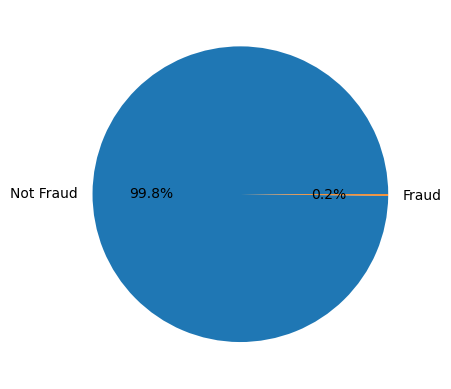

In [192]:
neg_class = data[data['Class'] == 0]
pos_class = data[data['Class'] == 1]
neg_class_count, pos_class_count = data['Class'].value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(data) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(data) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
plt.savefig('images/pie_chart_class_dis.png')
plt.show()

#### Why is this bad?
1. Most of classifiers (like Logistic Regression) is built on the assumption that the dataset is balanced.
2. Standard classification algorithms often perform poorly on such datasets, as they tend to classify most instances as the majority class to achieve high overall accuracy, ignoring the minority class.
3. The usual metrics used for gauging a model's performance, such as Accuracy, Precision, AUC-ROC and F1, are highly senstitive to the class imbalance and may indicate misleading results.

#### What can be done?
We have three options in hand. We can choose either one or more:
1. Process the Dataset
2. Use better models (which is out of scope for our problem statement)
3. Use better metrics

In [193]:
x, y = data.drop(columns=['Class']), data['Class']

In [194]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.15, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Percentage of Positive Class data points: 0.17266662535886157
Percentage of Negative Class data points: 99.82733337464114
Ratio of number of Negative Class to that of Positive Class : 578.1507177033493


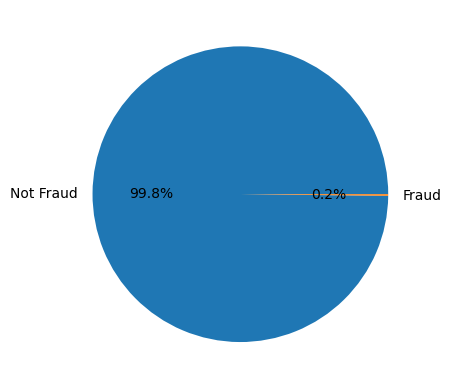

In [195]:
neg_class = y_train[y_train == 0]
pos_class = y_train[y_train == 1]
neg_class_count, pos_class_count = y_train.value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(y_train) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(y_train) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
# plt.savefig('images/pie_chart_class_dis.png')
plt.show()

Percentage of Positive Class data points: 0.1732128645662656
Percentage of Negative Class data points: 99.82678713543373
Ratio of number of Negative Class to that of Positive Class : 576.3243243243244


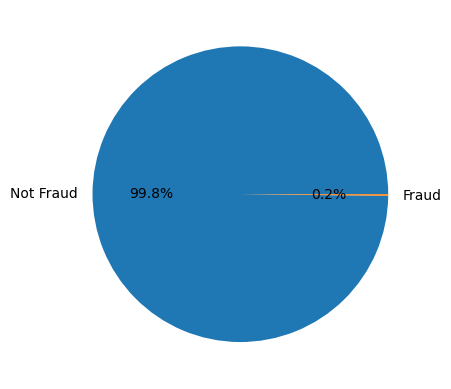

In [196]:
neg_class = y_test[y_test == 0]
pos_class = y_test[y_test == 1]
neg_class_count, pos_class_count = y_test.value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(y_test) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(y_test) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
# plt.savefig('images/pie_chart_class_dis.png')
plt.show()

In [197]:
min_x = X_train[y_train == 1]
min_y = y_train[y_train == 1]

## Pipeline

In [198]:
def report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from sklearn
    """

    y_test = y_test.to_numpy()
    x = ["Fraud", "Not Fraud"]
    actual_fraud, predict_fraud = y_test[np.where(y_test == 1)[0]], y_pred[np.where(y_test == 1)[0]]
    actual_not_fraud, predict_not_fraud = y_test[np.where(y_test == 0)[0]], y_pred[np.where(y_test == 0)[0]]

    report = {
        "Fraud": {
            "precision": precision_score(actual_fraud, predict_fraud),
            "recall": recall_score(actual_fraud, predict_fraud),
            "f1": f1_score(actual_fraud, predict_fraud),
            "bal_acc": balanced_accuracy_score(actual_fraud, predict_fraud),
            "accuracy": accuracy_score(actual_fraud, predict_fraud),
            "size": len(actual_fraud)
        },
        "Not Fraud": {
            "precision": precision_score(actual_not_fraud, predict_not_fraud),
            "recall": recall_score(actual_not_fraud, predict_not_fraud),
            "f1": f1_score(actual_not_fraud, predict_not_fraud),
            "bal_acc": balanced_accuracy_score(actual_not_fraud, predict_not_fraud),
            "accuracy": accuracy_score(actual_not_fraud, predict_not_fraud),
            "size": len(actual_not_fraud)
        },
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        "roc_curve": roc_curve(y_test, y_pred),
        "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred),
        "avg_p": average_precision_score(y_test, y_pred)
    }
    fraud, not_fraud = report['Fraud'], report['Not Fraud']

    fig, axs = plt.subplots(3, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#D55E00',  # Vermillion
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        if i != 'size':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i.capitalize()} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylabel(f"Log of {i.capitalize()} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report_skelearn.png")
    plt.show()

    cm = ConfusionMatrixDisplay(confusion_matrix=report['confusion_matrix'], display_labels=x[::-1])
    cm.plot()
    plt.savefig(f"images/Confusion_mat_{name}.png")
    plt.show()

    # pr = PrecisionRecallDisplay.from_predictions(y_test, y_pred)
    # pr.plot()
    # plt.savefig(f"images/PR_Curve_{name}.png")
    # plt.show()

    # roc = RocCurveDisplay.from_predictions(y_test, y_pred)
    # roc.plot()
    # plt.savefig(f"images/ROC_Curve_{name}.png")
    # plt.show()

    return report

In [199]:
def imbalanced_report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from imblearn
    """

    report = classification_report_imbalanced(y_test, y_pred,
    labels=[0, 1], target_names=['Not Fraud', 'Fraud'], output_dict=True)
    d = {
        "pre": "Precison", "rec": "Recall",
        "spe": "Specificity", "f1": "F1 Score",
        "geo": "FM Index", "iba": "IBA",
        "sup": "Support", "avg_pre": "Average Precision",
        "avg_rec": "Average Recall", "avg_spe": "Average Specificity",
        "avg_f1": "Average F1 Score", "avg_geo": "Average FM Index",
        "avg_iba": "Average IBA", "total_support": "Total Support"
    }
    better_report = {
        "Fraud": dict(), "Not Fraud": dict(), 
        "Average Precision": 0,"Average Recall": 0,
        "Average Specificity": 0,
        "Average F1 Score": 0,
        "Average FM Index": 0,
        "Average Index Balanced Accuracy": 0,
        "Total Support": 0
    }
    for i in report:
        if i == "Fraud":
            k = report[i]
            for j in k:
                better_report["Fraud"][d[j]] = k[j]
        elif i == "Not Fraud":
            k = report[i]
            for j in k:
                better_report["Not Fraud"][d[j]] = k[j]
        else:
            better_report[d[i]] = report[i]
    fraud, not_fraud = better_report['Fraud'], better_report['Not Fraud']

    fig, axs = plt.subplots(4, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        x = ["Fraud", "Not Fraud"]
        if i != 'Support':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylabel(f"Log of {i} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    axs[k, l].bar(x=["Fraud", "Not Fraud"], height=[np.log(len(pos_class)), np.log(len(neg_class))])
    axs[k, l].set_title("Sample Size Comparison")
    axs[k, l].set_xlabel(f"Class")
    axs[k, l].set_ylabel(f"Log of Size Value")
    for q in range(len(x)):
        axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report.png")
    plt.show()

    return better_report

In [200]:
def classify(train, test, name, balanced=False, gmm = None):
    """
        The main pipeline code
    """

    x_train, y_train = train
    x_test, y_test = test
    
    pipeline = []
    if balanced:  # if we want to test with balanced class weights
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs", class_weight='balanced')))
    else:
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs")))
    pipeline = Pipeline(pipeline)

    model = pipeline.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    r1 = report_generator(y_pred, y_test, name)
    r2 = imbalanced_report_generator(y_pred, y_test, name)
    
    k = ['precision','recall','f1','bal_acc','mcc','accuracy','roc_auc','avg_p']
    new_r1 = {i: r1[i] for i in k}
    new_r1['positive_likelihood_ratio'] = r1['likelihood_ratios'][0]
    new_r1['negative_likelihood_ratio'] = r1['likelihood_ratios'][1]
    new_r1['name'] = name
    df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    return model, r1, r2, df

In [201]:
classifiers = dict()
sk_reports = dict()
im_reports = dict()
total_df = dict()

## Straight Classification

### Unbalanced Logistic Regression

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


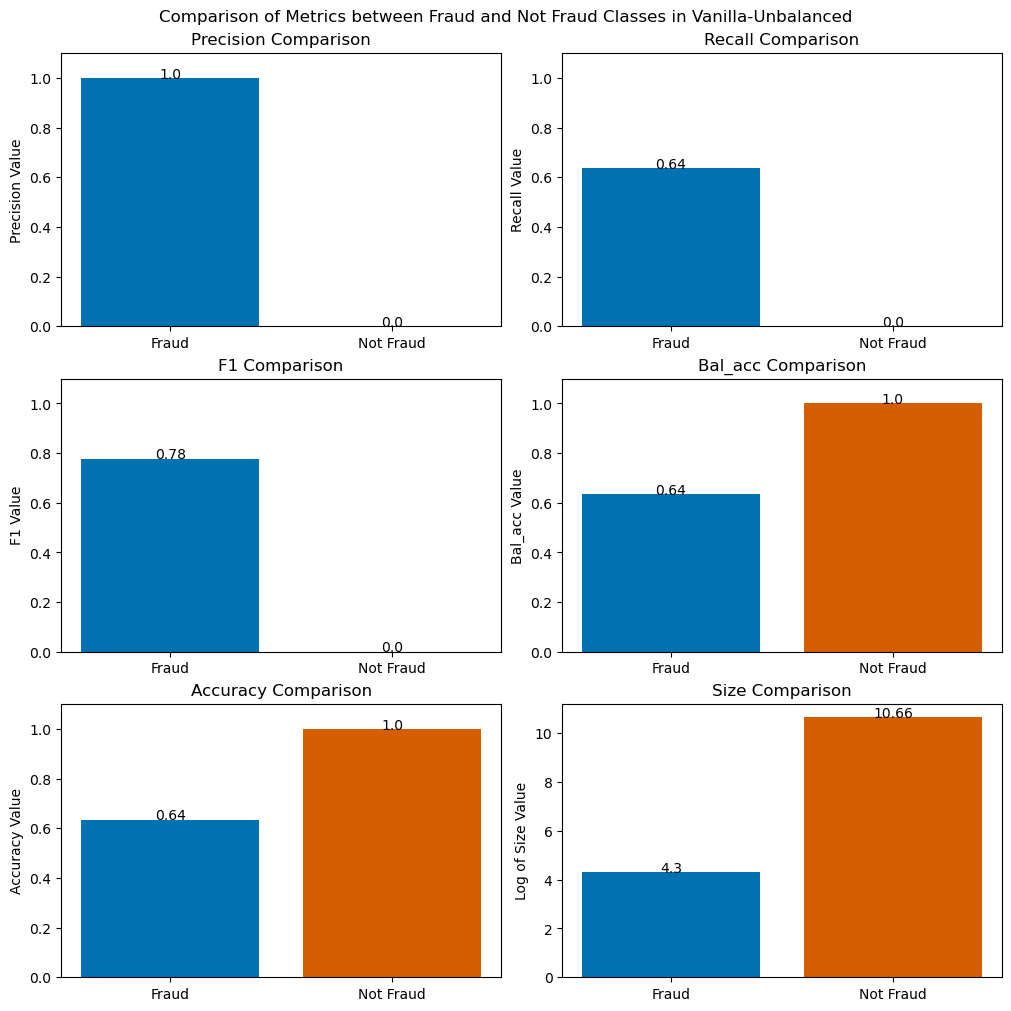

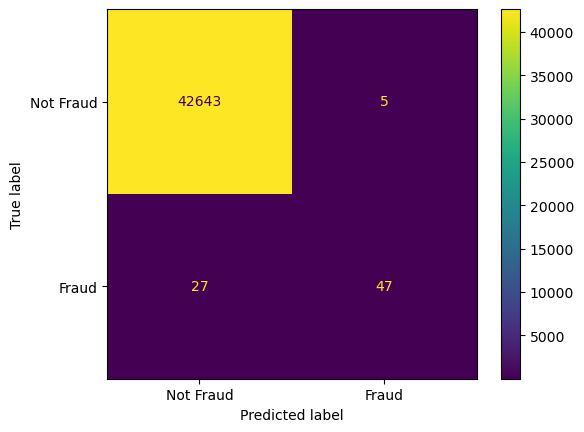

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


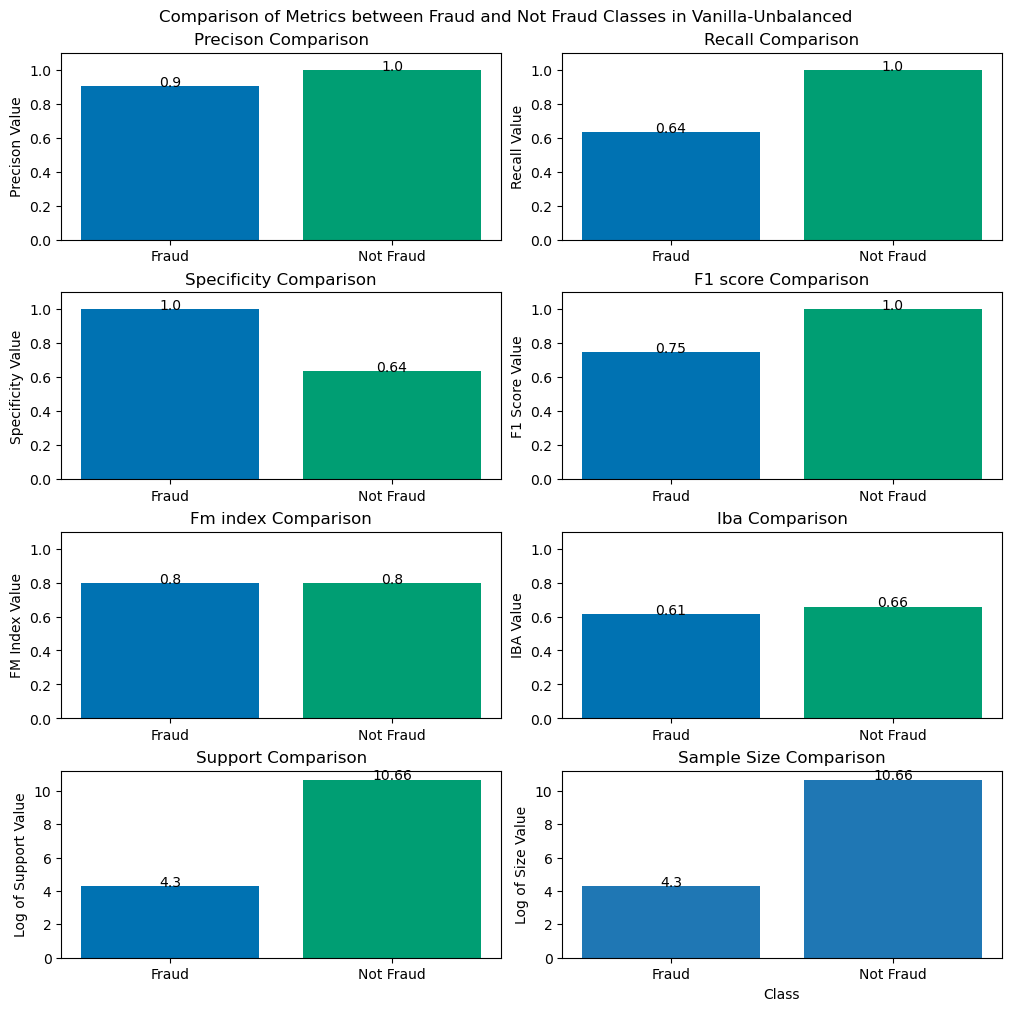

In [202]:
name="Vanilla-Unbalanced"
model, r1, r2, df = classify((X_train, y_train), (X_test, y_test), name=name, )
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

### Balanced Logistic Regression

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


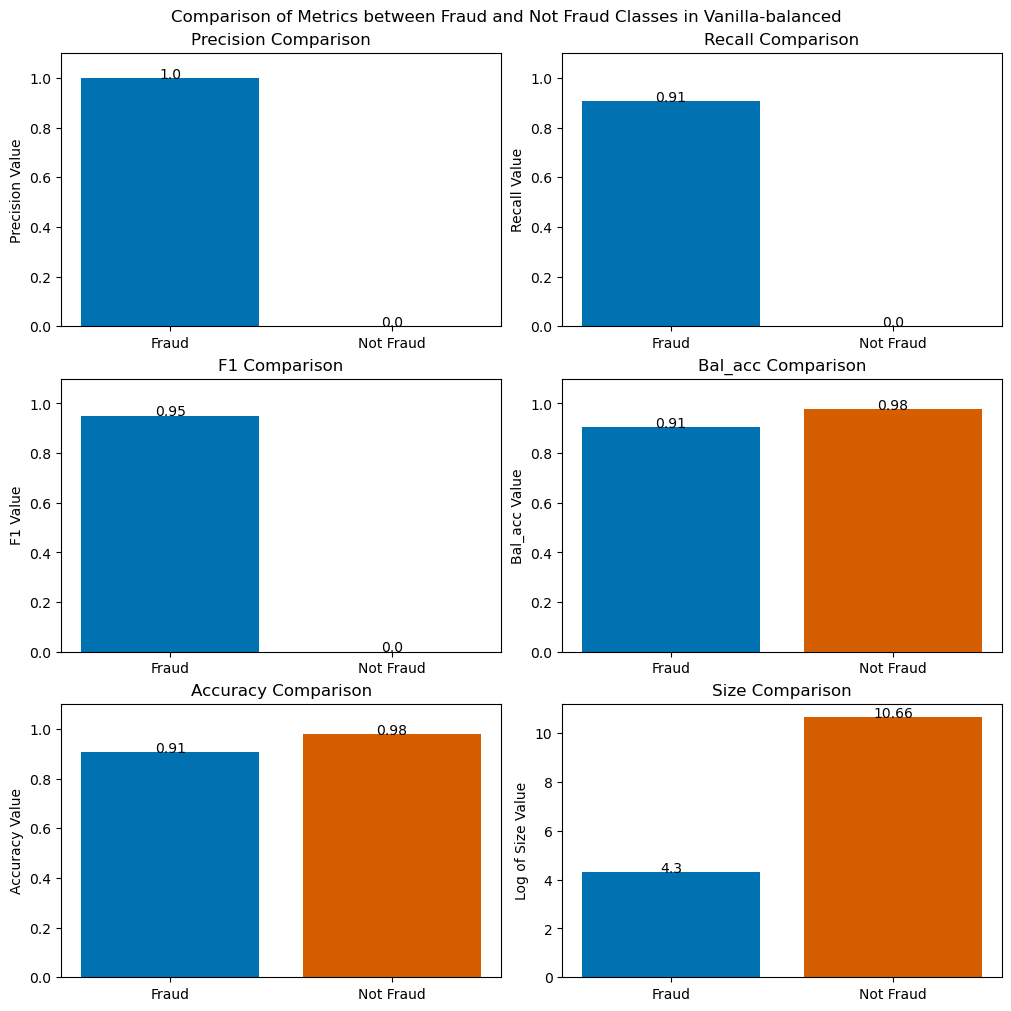

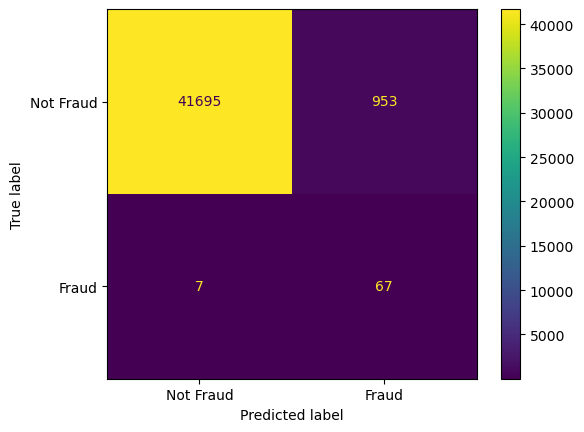

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


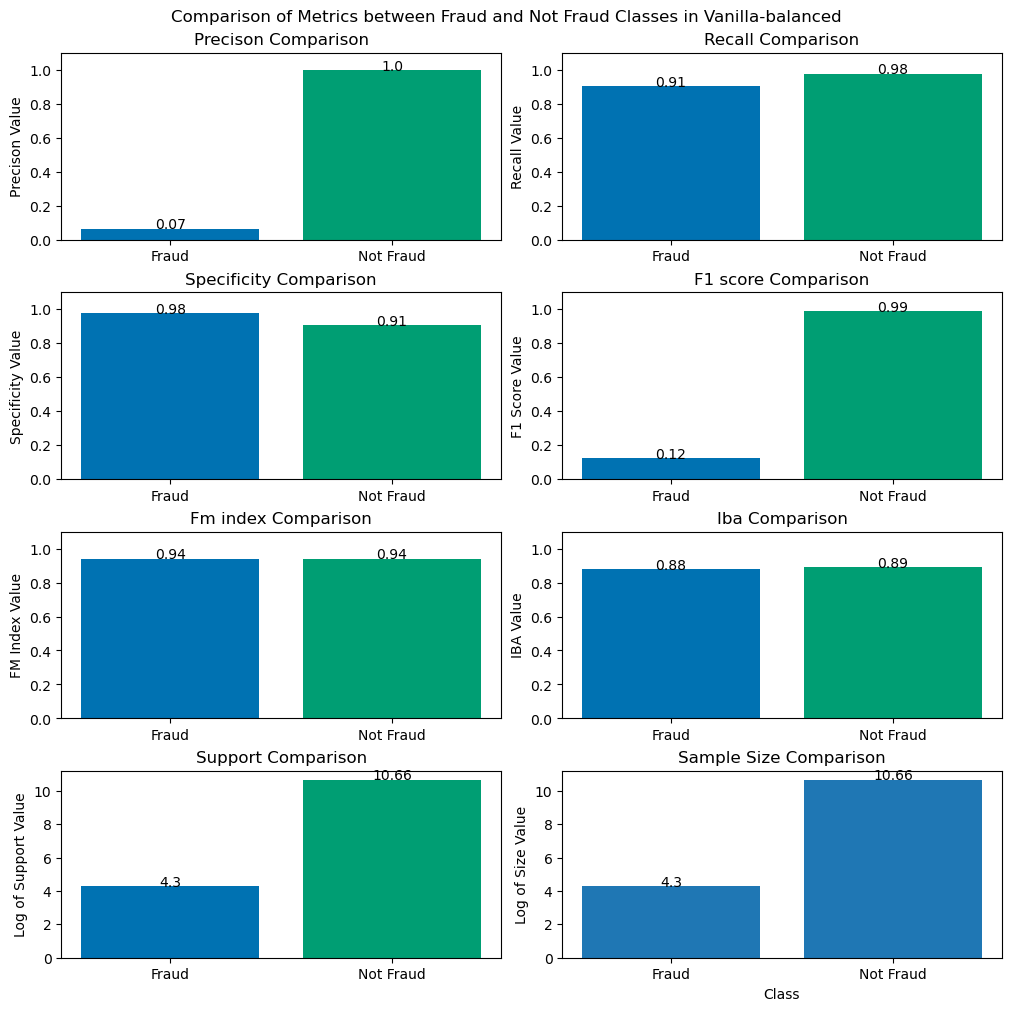

In [203]:
name = "Vanilla-balanced"
model, r1, r2, df = classify((X_train, y_train), (X_test, y_test), name=name, balanced=True)
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

## ClusterCentroids

In [204]:
cc = ClusterCentroids(sampling_strategy="majority",
    estimator=MiniBatchKMeans(n_clusters=25)
)
name = "ClusterCentroids(k=25)"

x_sampled, y_sampled = cc.fit_resample(X_train, y_train)
# model, r1, r2, df = classify((x_sampled, y_sampled), (X_test, y_test), name, cc)

# classifiers[name] = (model)
# sk_reports[name] = (r1)
# im_reports[name] = (r2)
# total_df[name] = (df)

Percentage of Positive Class data points: 50.0
Percentage of Negative Class data points: 50.0
Ratio of number of Negative Class to that of Positive Class : 1.0


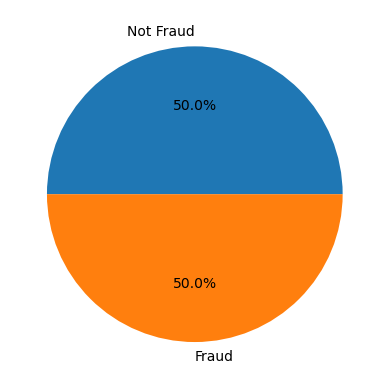

In [205]:
neg_class = y_sampled[y_sampled == 0]
pos_class = y_sampled[y_sampled == 1]
neg_class_count, pos_class_count = y_sampled.value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(y_sampled) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(y_sampled) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
# plt.savefig('images/pie_chart_class_dis.png')
plt.show()

## Gaussian Mixture Models (GMMs)

### Difference between GMM-based Synthetic Sampling and SMOTE

SMOTE employs a localized interpolation technique and works by creating synthetic instances of the minority class by linear interpolation between existing minority samples and their nearest neighbors. Its reliance on linear interpolation between neighboring points can be a limitation. If the minority class has a complex, non-linear structure, SMOTE may generate samples that are not representative of the true underlying distribution. It can also be sensitive to noisy data and create synthetic samples in inappropriate regions of the feature space.<br>

GMM-based methods learn and sample from an estimated underlying probability distribution of the data. It assumes that the minority class data can be represented by a mixture of several Gaussian distributions. By this, it does soft clustering by assuming each data point has some probability of belonging to a cluster. The first step involves fitting a GMM to the existing minority class data. This process estimates the parameters of these Gaussian components, such as their means, covariances, and weights, effectively learning the underlying structure and density of the data. It can thus capture complex distributions, generates more realistic samples, and more robust to noise.

### Why GMMs are better

It learns a probabilistic model that can represent a dataset as a combination of multiple, simpler Gaussian (normal) distributions. This "mixture" approach gives them the flexibility to model data that doesn't fit a single, simple shape. The "fraud" class might actually be have multiplpe clusters. A GMM can assign a separate Gaussian component to each of these cluster. When it generates new synthetic data, it can create samples that are representative of these specific clusters, preserving the rich, internal structure of the minority class Because a GMM is a combination of multiple Gaussian distributions, each with its own covariance matrix, it can model these complex shapes with high fidelity.

### GMM Implementation on Minority Class (n_min = 1e5)

In [206]:
new_min_size = 200000

In [207]:
gmms = []
new_x = []
new_y = []

#### Diagonal Covariance Type

Diagonal covariance allows each cluster to have different variances along each axis with each cluster being ellipsoidal. 

In [208]:
n_components = np.arange(1, 51)
models1 = [GaussianMixture(n, covariance_type='diag', random_state=0).fit(min_x)
          for n in n_components]
bic = [m.bic(min_x) for m in models1]
aic = [m.aic(min_x) for m in models1]

1. Akaike Information Criterion (AIC): This criterion estimates the prediction error and, therefore, the relative quality of statistical models for a given set of data. It's great for finding the best model for prediction.
2. Bayesian Information Criterion (BIC): This is similar to AIC but generally applies a larger penalty for model complexity, especially as the dataset size grows. This means BIC tends to favor simpler models compared to AIC.

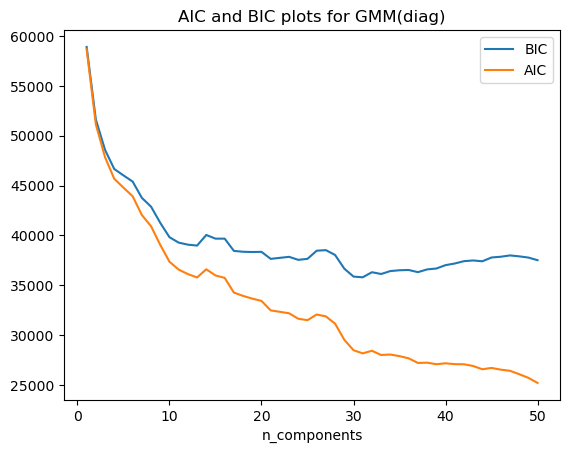

In [209]:
plt.plot(n_components, bic, label='BIC')
plt.plot(n_components, aic, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(diag)")
plt.savefig(f"images/AIC and BIC plots for GMM(diag).png")
plt.show()

Elbow point is 13

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]


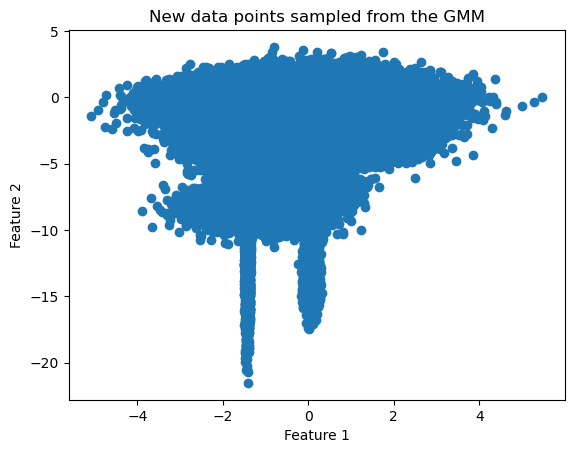

In [210]:
gmm = GaussianMixture(n_components=13, covariance_type='diag').fit(min_x)
probs = gmm.predict_proba(min_x)
print(probs[:5].round(3))
Xnew, ynew = gmm.sample(new_min_size)
plt.title("New data points sampled from the GMM")
plt.savefig("images/New data points sampled from the GMM(13, diag).png")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2") 
plt.scatter(Xnew[:, 0], Xnew[:, 1])
plt.show()

In [211]:
gmms.append(gmm)
new_x.append(Xnew)
new_y.append(ynew)

#### Full Covariance Type

Full covariance allows each cluster to have its own arbitrary covariance matrix.

In [212]:
n_components = np.arange(1, 10)
models1 = [GaussianMixture(n, covariance_type='full', random_state=0).fit(min_x) for n in n_components]
bic1 = [m.bic(min_x) for m in models1]
aic1 = [m.aic(min_x) for m in models1]

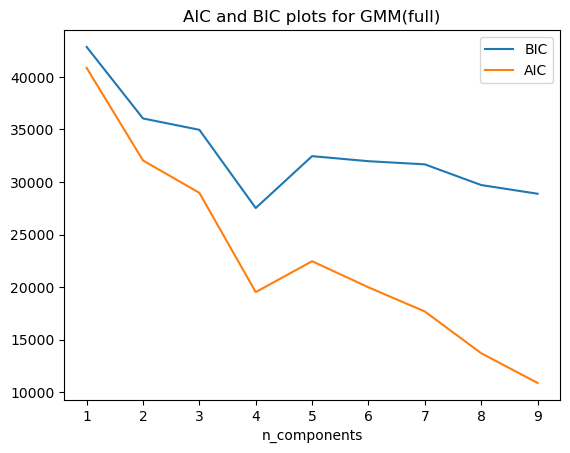

In [213]:
plt.plot(n_components, bic1, label='BIC')
plt.plot(n_components, aic1, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(full)")
plt.savefig(f"images/AIC and BIC plots for GMM(full).png")
plt.show()

Elbow point is 3

[[0.    0.    1.   ]
 [0.    1.    0.   ]
 [0.662 0.    0.338]
 [1.    0.    0.   ]
 [0.001 0.    0.999]]


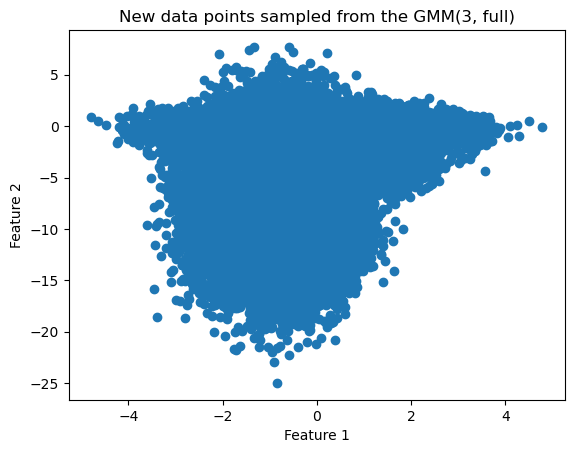

In [214]:
gmm1 = GaussianMixture(n_components=3, covariance_type='diag').fit(min_x)
probs = gmm1.predict_proba(min_x)
print(probs[:5].round(3))
Xnew1, ynew1 = gmm1.sample(new_min_size)
plt.title("New data points sampled from the GMM(3, full)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("images/New data points sampled from the GMM(3, full).png")
plt.scatter(Xnew1[:, 0], Xnew1[:, 1])
plt.show()

In [215]:
gmms.append(gmm1)
new_x.append(Xnew1)
new_y.append(ynew1)

#### Spherical Covariance Type

Spherical covariance forces each Gaussian cluster to have the same variance in all directions with the cluster shapes being spherical.

In [216]:
n_components = np.arange(1, 10)
models2 = [GaussianMixture(n, covariance_type='spherical', random_state=0).fit(min_x) for n in n_components]
bic2 = [m.bic(min_x) for m in models2]
aic2 = [m.aic(min_x) for m in models2]

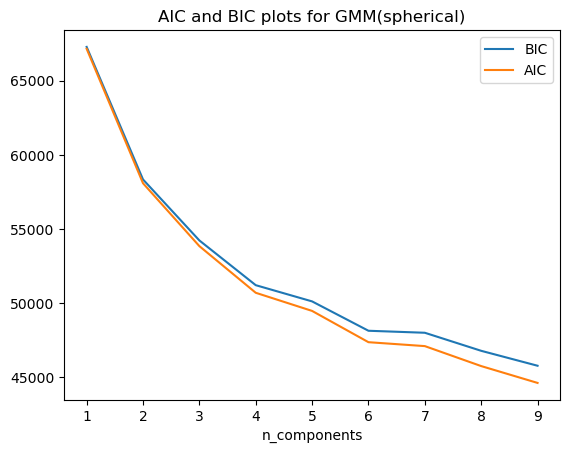

In [217]:
plt.plot(n_components, bic2, label='BIC')
plt.plot(n_components, aic2, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(spherical)")
plt.savefig(f"images/AIC and BIC plots for GMM(spherical).png")
plt.show()

Elbow point is 3

[[0.    0.    1.   ]
 [0.    1.    0.   ]
 [1.    0.    0.   ]
 [0.983 0.    0.017]
 [0.    0.    1.   ]]


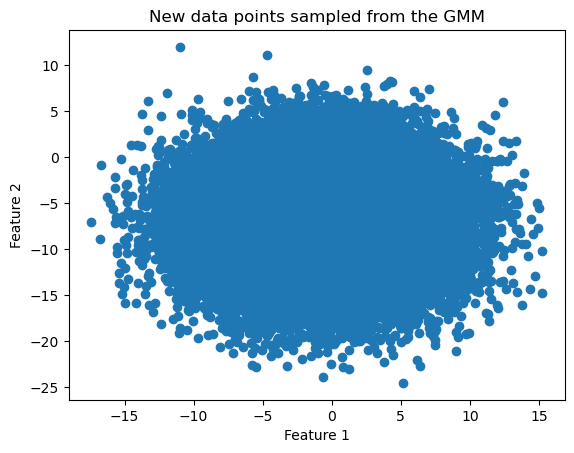

In [218]:
gmm2 = GaussianMixture(n_components=3, covariance_type='spherical').fit(min_x)
probs = gmm2.predict_proba(min_x)
print(probs[:5].round(3))
Xnew2, ynew2 = gmm2.sample(new_min_size)
plt.title("New data points sampled from the GMM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("images/New data points sampled from the GMM(3, spherical).png")
plt.scatter(Xnew2[:, 0], Xnew2[:, 1])
plt.show()

In [219]:
gmms.append(gmm2)
new_x.append(Xnew2)
new_y.append(ynew2)

#### Creating Dataset

In [220]:
new_x_train, new_y_train = [], []
maj_x, maj_y = X_train[y_train == 0], y_train[y_train == 0]

for i in range(len(new_x)):
    xnew, ynew = new_x[i], np.ones_like(new_y[i])
    X = np.concatenate((maj_x, xnew), axis=0)
    y = np.concatenate((maj_y, ynew), axis=0)
    new_x_train.append(X)
    new_y_train.append(y)

### GMM Implementation on Minority Class (n_min = clustered size)

In [221]:
new_min_size = len(y_sampled[y_sampled == 0])

In [222]:
gmms = []
new_x = []
new_y = []

#### Diagonal Covariance Type

In [223]:
n_components = np.arange(1, 51)
models1 = [GaussianMixture(n, covariance_type='diag', random_state=0).fit(min_x)
          for n in n_components]
bic = [m.bic(min_x) for m in models1]
aic = [m.aic(min_x) for m in models1]

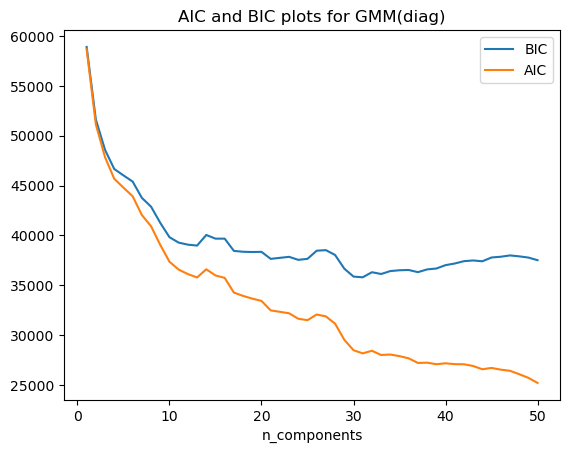

In [224]:
plt.plot(n_components, bic, label='BIC')
plt.plot(n_components, aic, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(diag)")
plt.savefig(f"images/AIC and BIC plots for GMM(diag).png")
plt.show()

Elbow point is 13

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


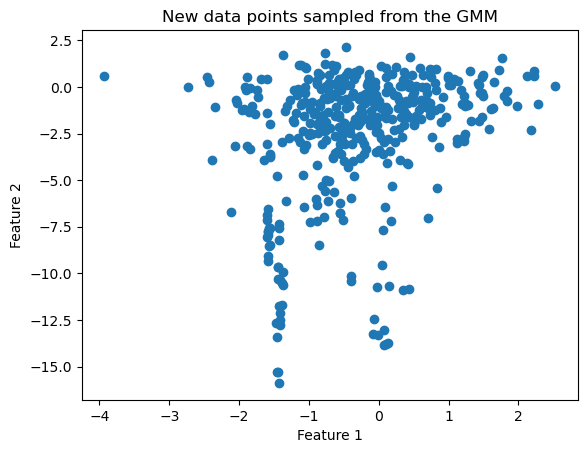

In [225]:
gmm = GaussianMixture(n_components=13, covariance_type='diag').fit(min_x)
probs = gmm.predict_proba(min_x)
print(probs[:5].round(3))
Xnew, ynew = gmm.sample(new_min_size)
plt.title("New data points sampled from the GMM")
plt.savefig("images/New data points sampled from the GMM(13, diag).png")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2") 
plt.scatter(Xnew[:, 0], Xnew[:, 1])
plt.show()

In [226]:
gmms.append(gmm)
new_x.append(Xnew)
new_y.append(ynew)

#### Full Covariance Type

In [227]:
n_components = np.arange(1, 10)
models1 = [GaussianMixture(n, covariance_type='full', random_state=0).fit(min_x) for n in n_components]
bic1 = [m.bic(min_x) for m in models1]
aic1 = [m.aic(min_x) for m in models1]

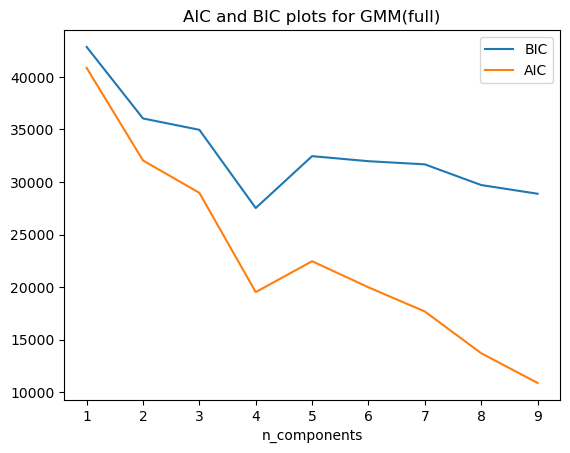

In [228]:
plt.plot(n_components, bic1, label='BIC')
plt.plot(n_components, aic1, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(full)")
plt.savefig(f"images/AIC and BIC plots for GMM(full).png")
plt.show()

Elbow point is 3

[[0.    0.    1.   ]
 [0.    1.    0.   ]
 [0.628 0.    0.372]
 [1.    0.    0.   ]
 [0.001 0.    0.999]]


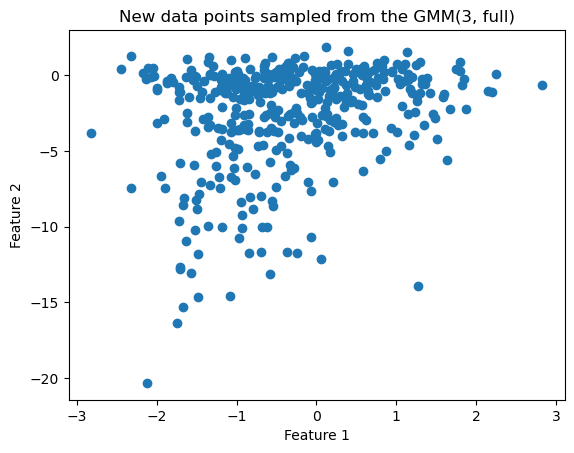

In [229]:
gmm1 = GaussianMixture(n_components=3, covariance_type='diag').fit(min_x)
probs = gmm1.predict_proba(min_x)
print(probs[:5].round(3))
Xnew1, ynew1 = gmm1.sample(new_min_size)
plt.title("New data points sampled from the GMM(3, full)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("images/New data points sampled from the GMM(3, full).png")
plt.scatter(Xnew1[:, 0], Xnew1[:, 1])
plt.show()

In [230]:
gmms.append(gmm1)
new_x.append(Xnew1)
new_y.append(ynew1)

#### Spherical Covariance Type

In [231]:
n_components = np.arange(1, 10)
models2 = [GaussianMixture(n, covariance_type='spherical', random_state=0).fit(min_x) for n in n_components]
bic2 = [m.bic(min_x) for m in models2]
aic2 = [m.aic(min_x) for m in models2]

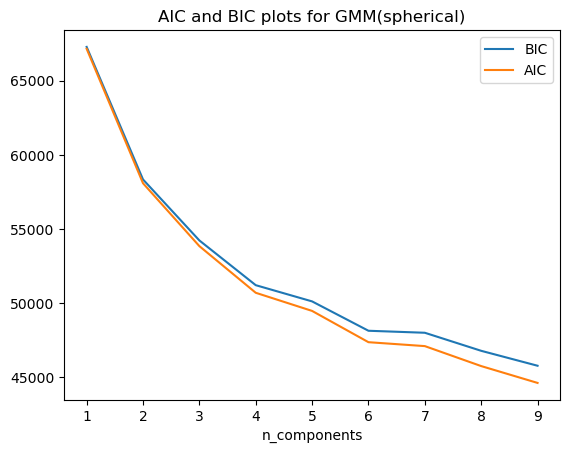

In [232]:
plt.plot(n_components, bic2, label='BIC')
plt.plot(n_components, aic2, label='AIC')
plt.legend(loc='best')
plt.xlabel('n_components')
plt.title("AIC and BIC plots for GMM(spherical)")
plt.savefig(f"images/AIC and BIC plots for GMM(spherical).png")
plt.show()

Elbow point is 3

[[0.    1.    0.   ]
 [1.    0.    0.   ]
 [0.    0.    1.   ]
 [0.    0.017 0.983]
 [0.    1.    0.   ]]


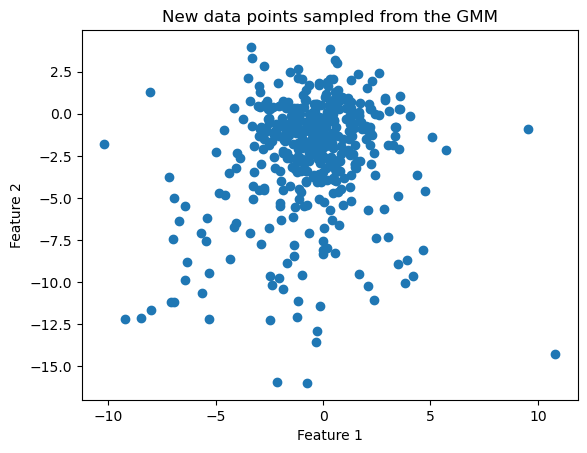

In [233]:
gmm2 = GaussianMixture(n_components=3, covariance_type='spherical').fit(min_x)
probs = gmm2.predict_proba(min_x)
print(probs[:5].round(3))
Xnew2, ynew2 = gmm2.sample(new_min_size)
plt.title("New data points sampled from the GMM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("images/New data points sampled from the GMM(3, spherical).png")
plt.scatter(Xnew2[:, 0], Xnew2[:, 1])
plt.show()

In [234]:
gmms.append(gmm2)
new_x.append(Xnew2)
new_y.append(ynew2)

#### Creating Datasets

In [235]:
new_x_train1, new_y_train1 = [], []
maj_x, maj_y = x_sampled[y_sampled == 0], y_sampled[y_sampled == 0]

for i in range(len(new_x)):
    xnew, ynew = new_x[i], np.ones_like(new_y[i])
    X = np.concatenate((maj_x, xnew), axis=0)
    y = np.concatenate((maj_y, ynew), axis=0)
    new_x_train1.append(X)
    new_y_train1.append(y)

## Compare Methods

Percentage of Positive Class data points: 45.28298469208703
Percentage of Negative Class data points: 54.71701530791297
Ratio of number of Negative Class to that of Positive Class : 1.208335


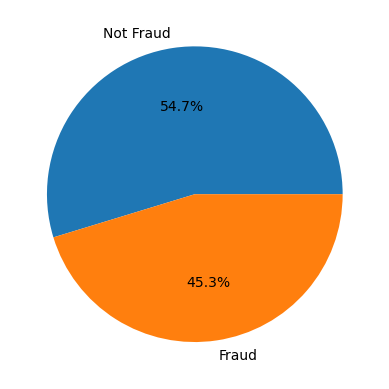

Percentage of Positive Class data points: 45.28298469208703
Percentage of Negative Class data points: 54.71701530791297
Ratio of number of Negative Class to that of Positive Class : 1.208335


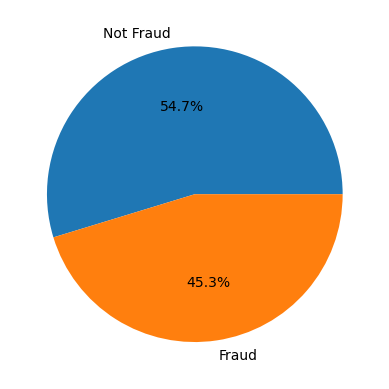

Percentage of Positive Class data points: 45.28298469208703
Percentage of Negative Class data points: 54.71701530791297
Ratio of number of Negative Class to that of Positive Class : 1.208335


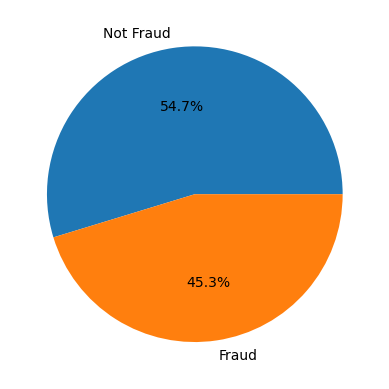

In [237]:
for y in new_y_train:
    neg_class = y[y == 0]
    pos_class = y[y == 1]
    neg_class_count, pos_class_count = len(neg_class), len(pos_class)
    print(f"Percentage of Positive Class data points: {len(pos_class)/ len(y) * 100}")
    print(f"Percentage of Negative Class data points: {len(neg_class)/ len(y) * 100}")
    print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")
    plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
    plt.savefig('images/pie_chart_class_dis_gmm_cbu.png')
    plt.show()

Percentage of Positive Class data points: 50.0
Percentage of Negative Class data points: 50.0
Ratio of number of Negative Class to that of Positive Class : 1.0


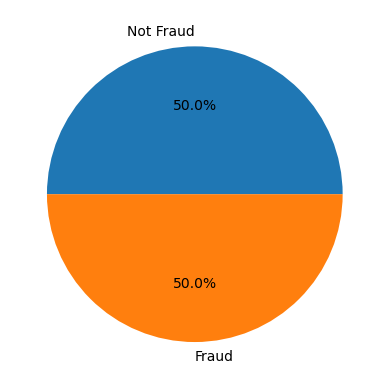

Percentage of Positive Class data points: 50.0
Percentage of Negative Class data points: 50.0
Ratio of number of Negative Class to that of Positive Class : 1.0


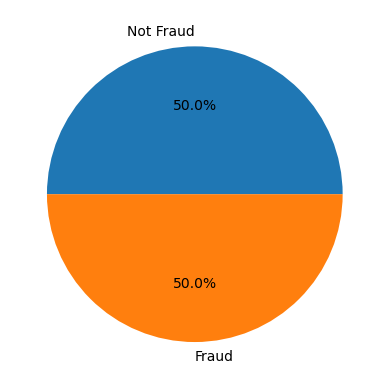

Percentage of Positive Class data points: 50.0
Percentage of Negative Class data points: 50.0
Ratio of number of Negative Class to that of Positive Class : 1.0


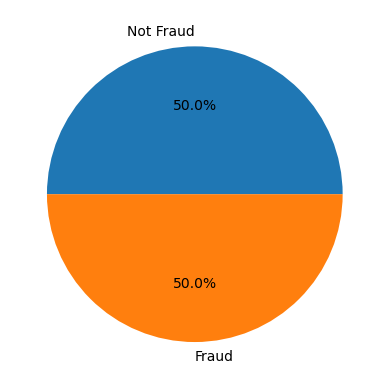

In [238]:
for y in new_y_train1:
    neg_class = y[y == 0]
    pos_class = y[y == 1]
    neg_class_count, pos_class_count = len(neg_class), len(pos_class)
    print(f"Percentage of Positive Class data points: {len(pos_class)/ len(y) * 100}")
    print(f"Percentage of Negative Class data points: {len(neg_class)/ len(y) * 100}")
    print(f"Ratio of number of Negative Class to that of Positive Class : {neg_class_count / pos_class_count}")
    plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
    plt.savefig('images/pie_chart_class_dis_gmm_cbu1.png')
    plt.show()

In [239]:
enum = (
    ("GMM-13-diag-unbal", 0, False),
    ("GMM-3-full-unbal", 1, False),
    ("GMM-3-spherical-unbal", 2, False),
    ("GMM-13-diag-bal", 0, True),
    ("GMM-3-full-bal", 1, True),
    ("GMM-3-spherical-bal", 2, True)
)

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


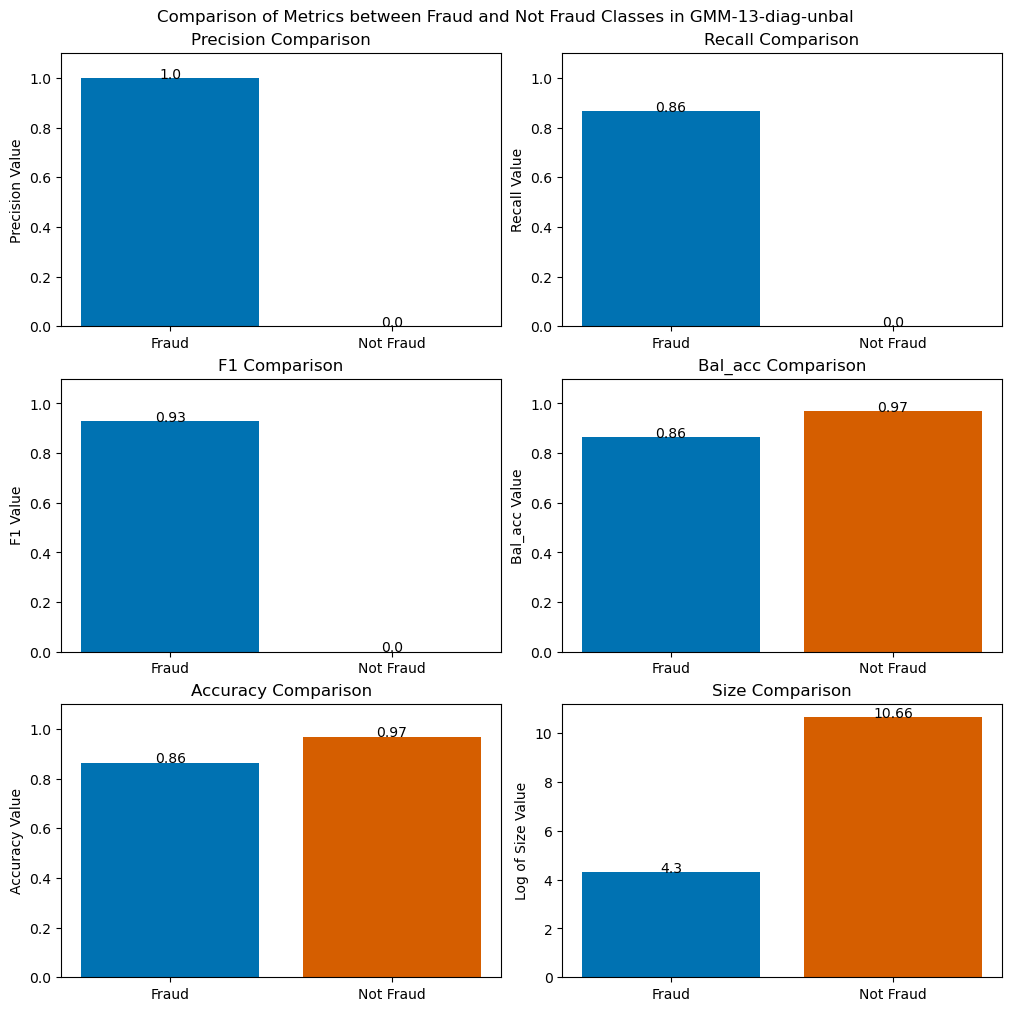

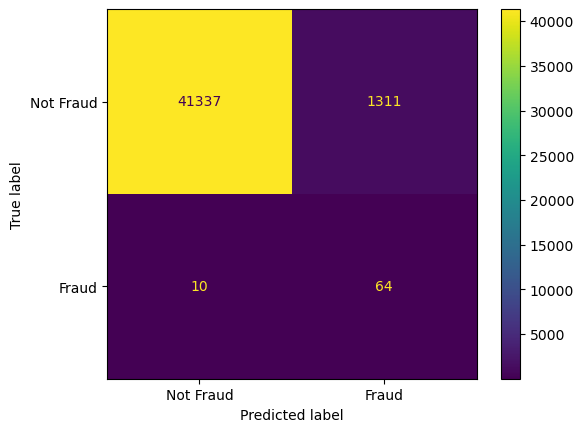

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


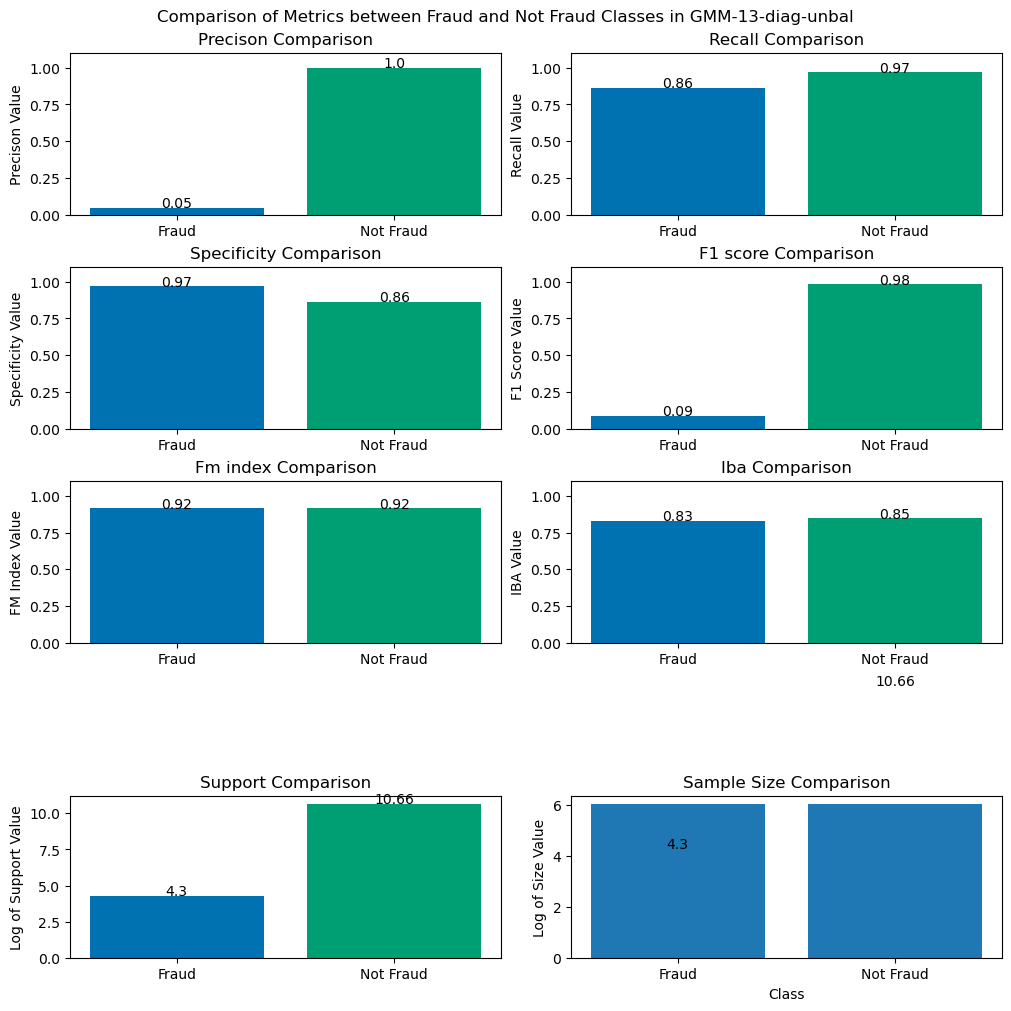

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


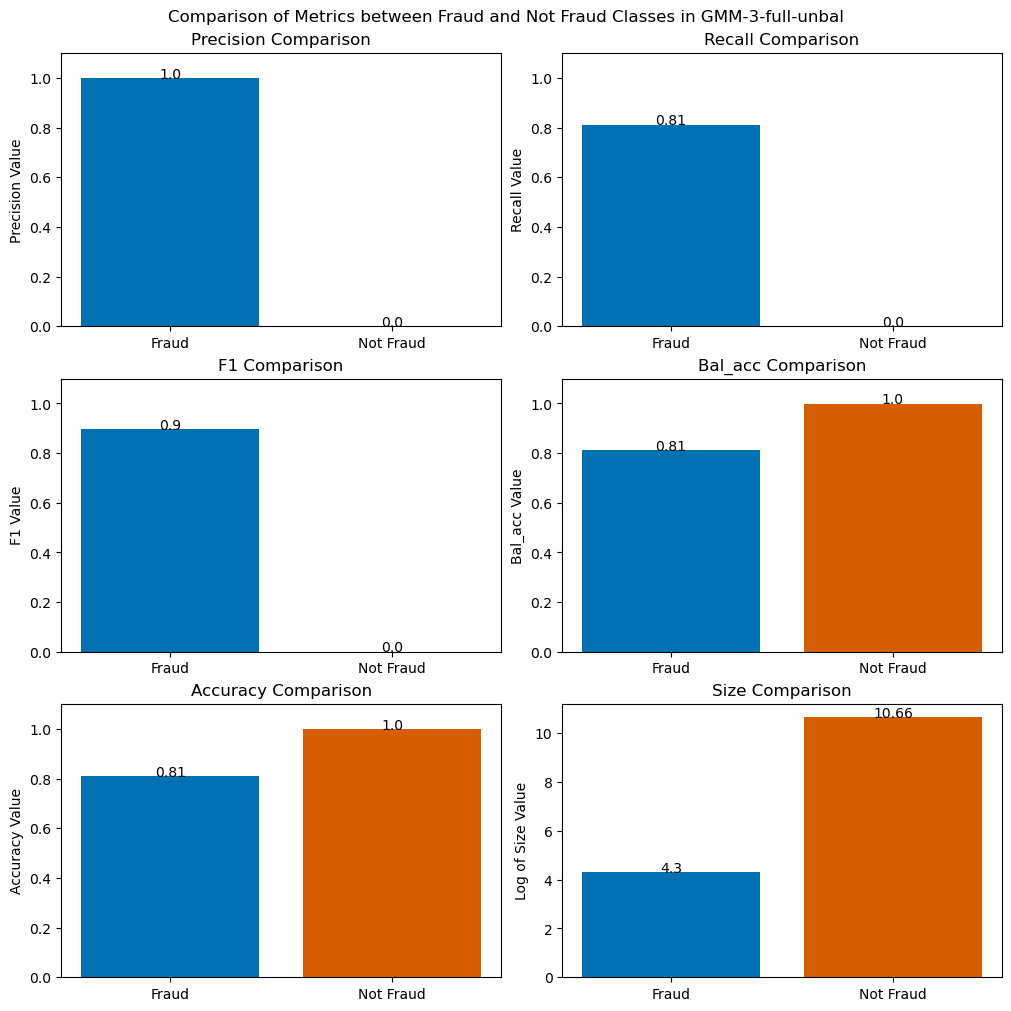

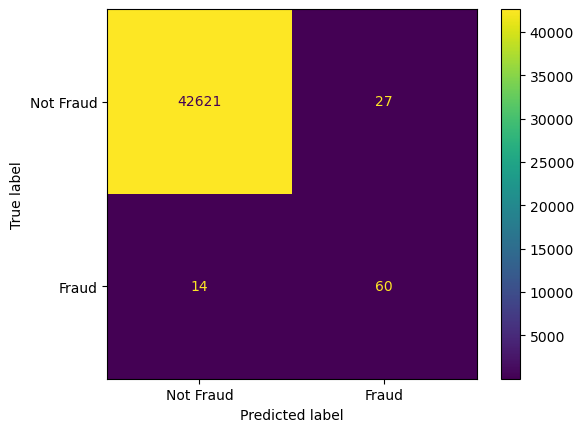

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


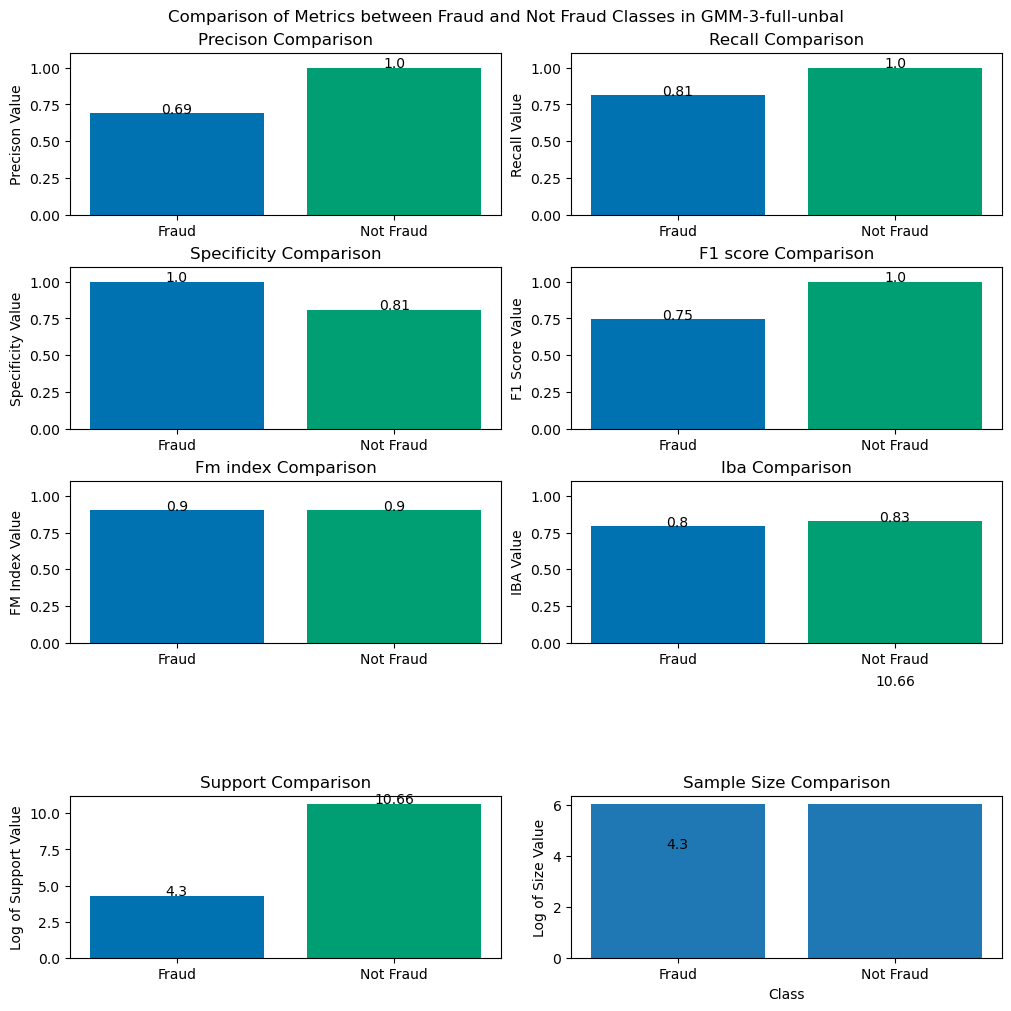

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


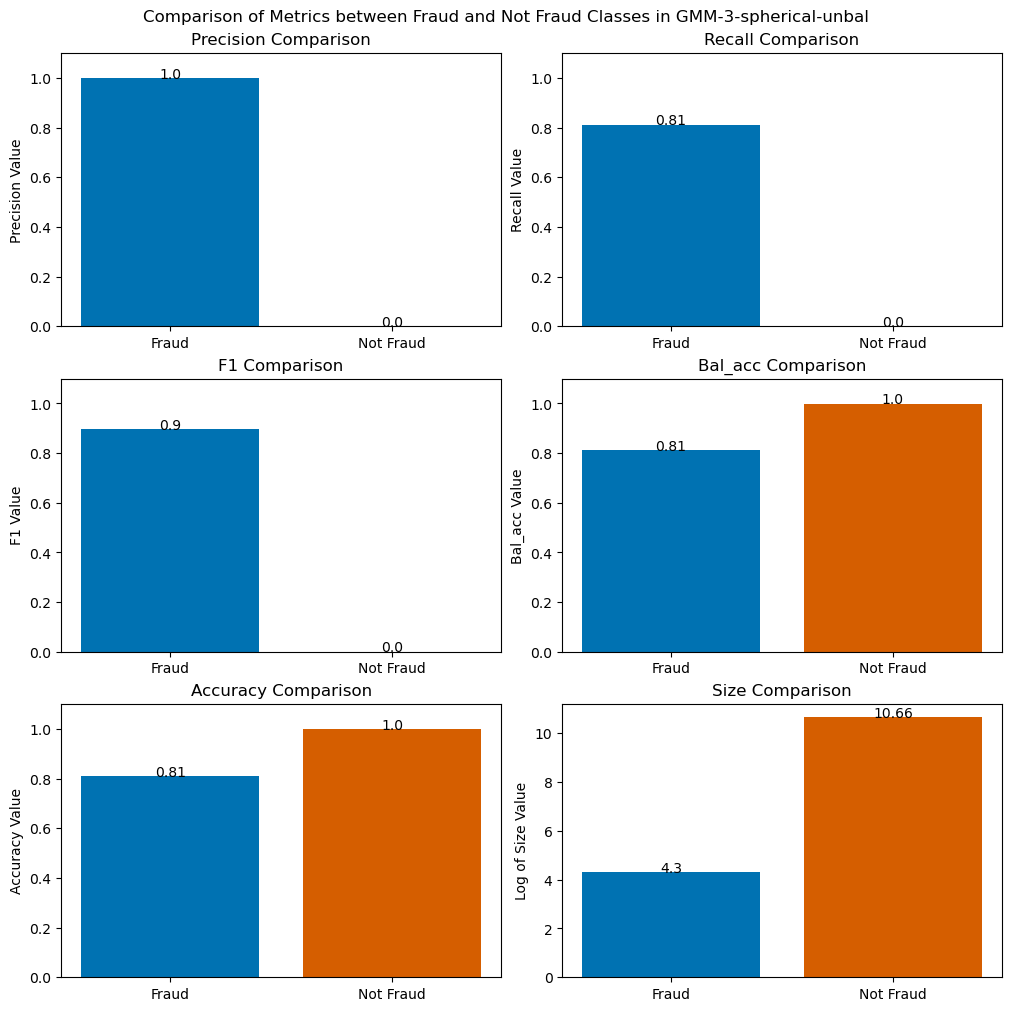

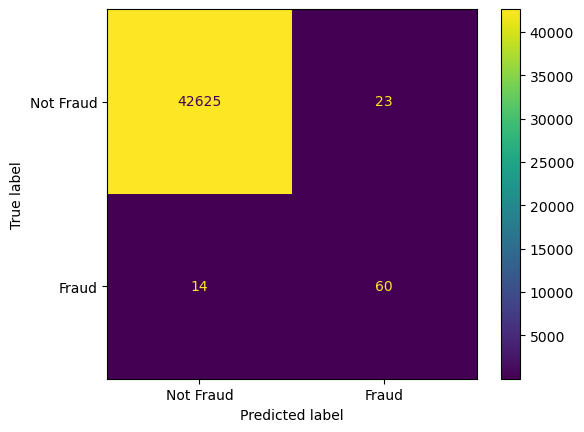

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


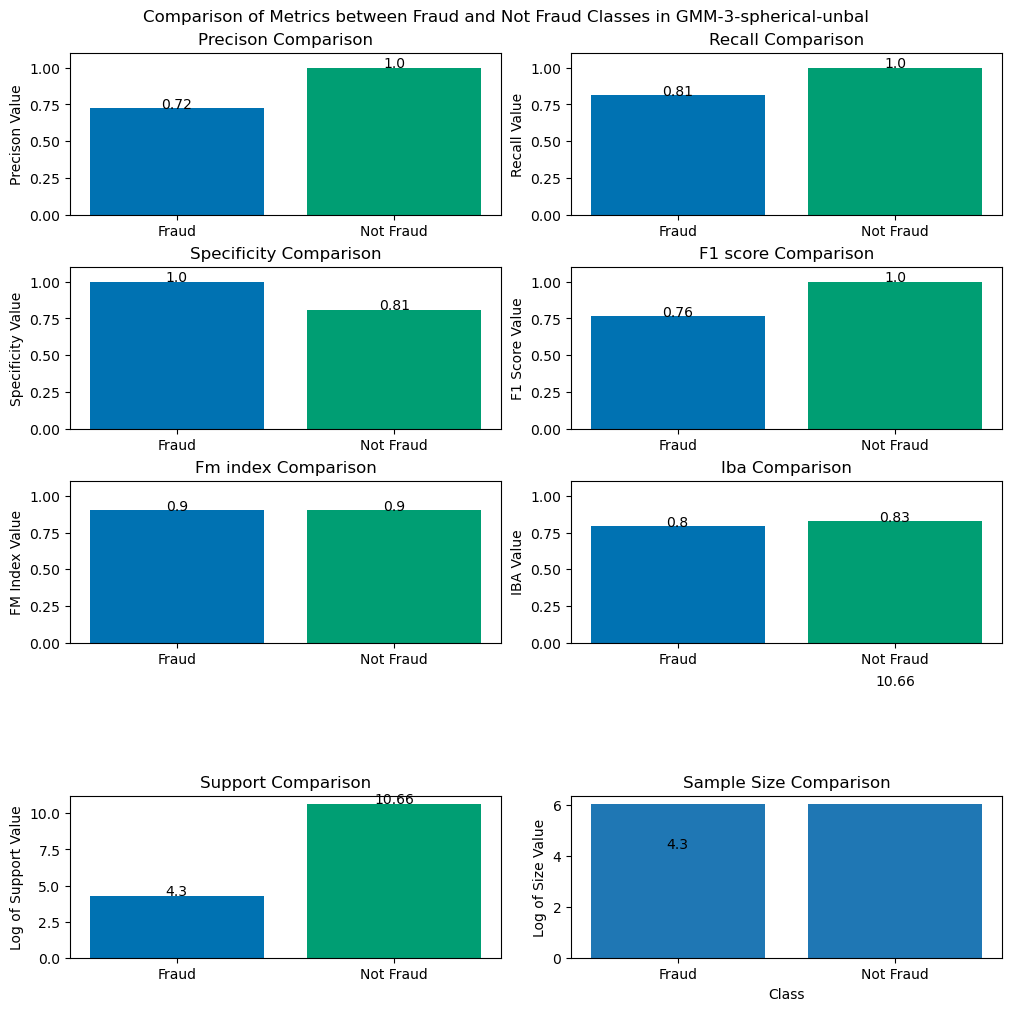

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


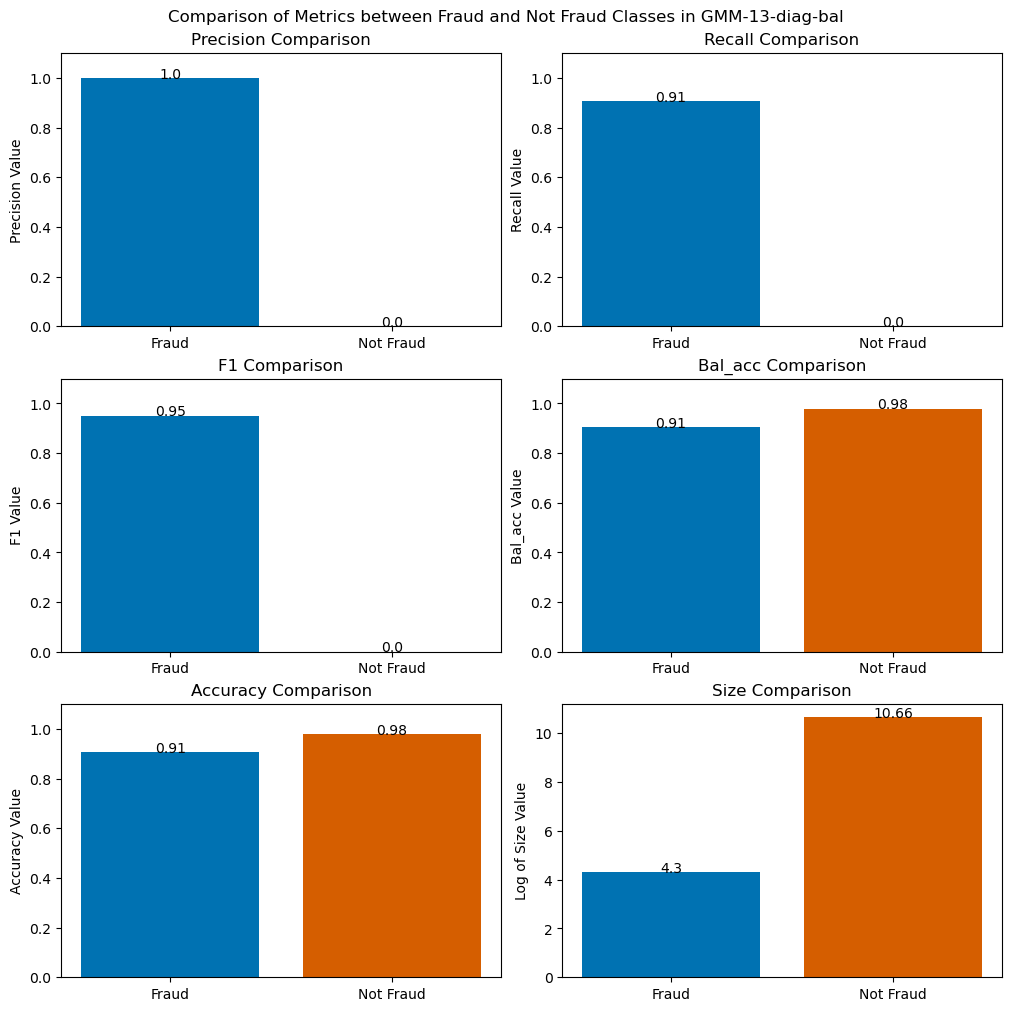

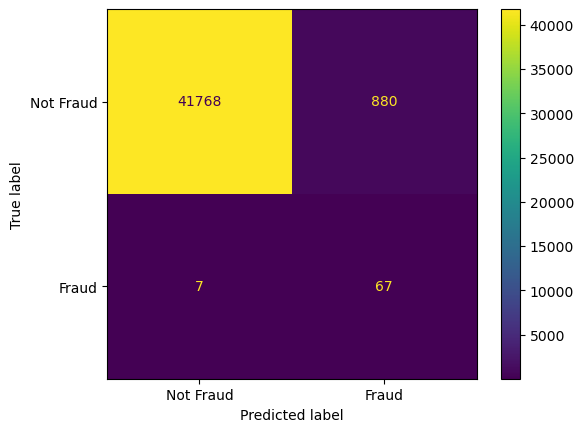

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


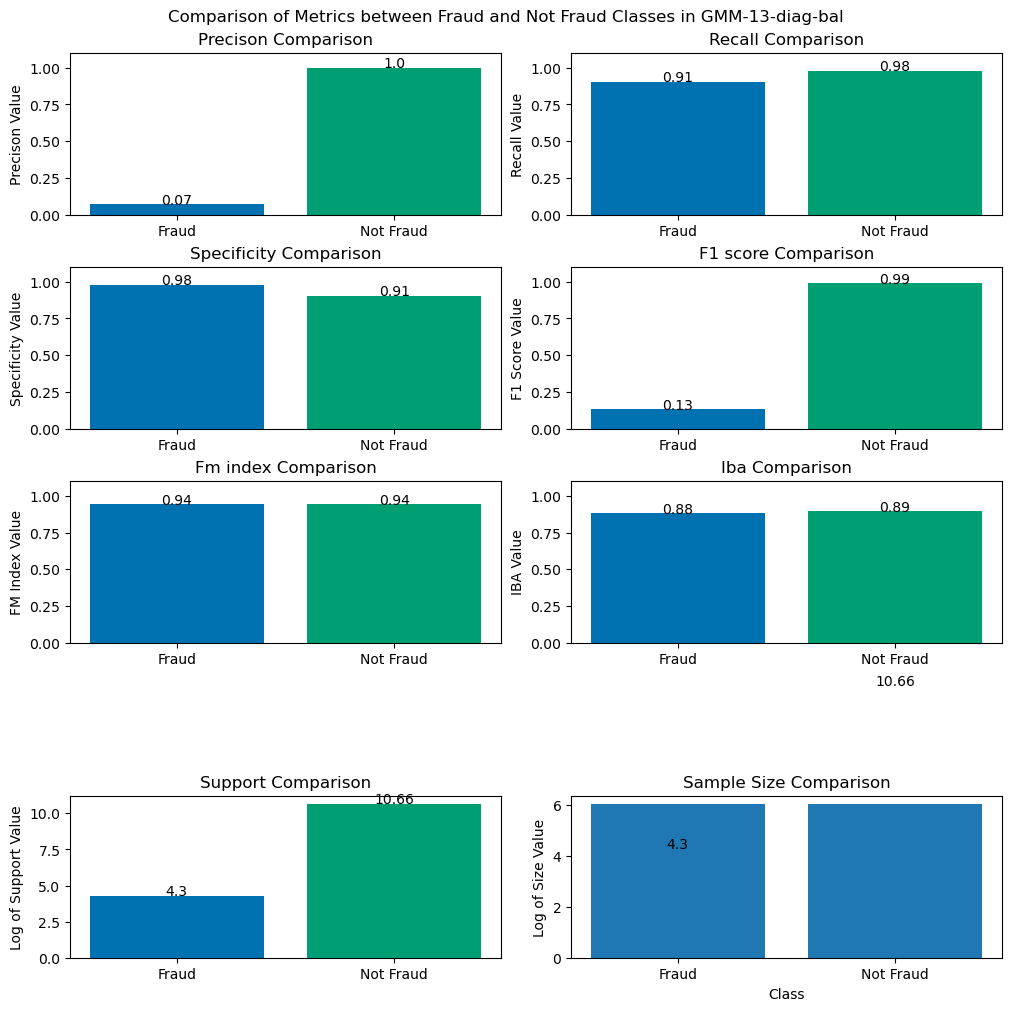

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


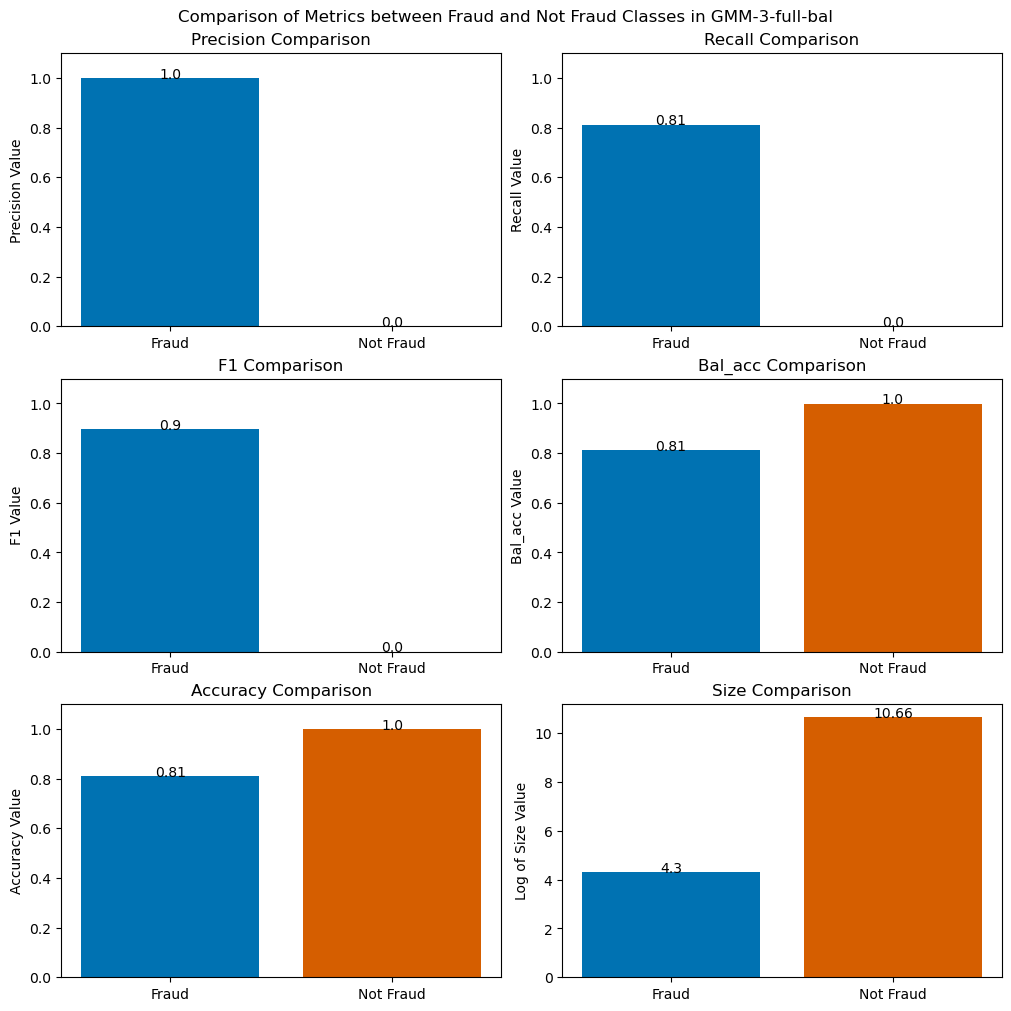

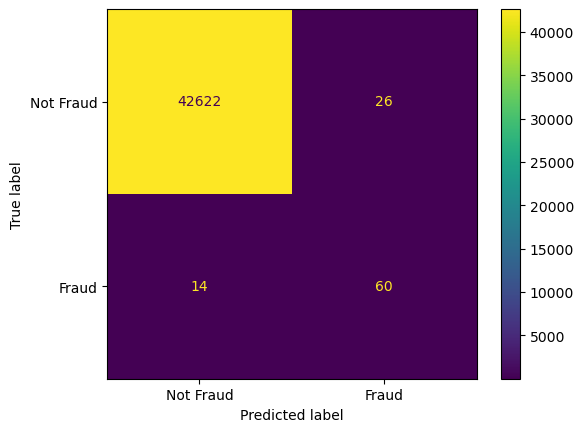

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


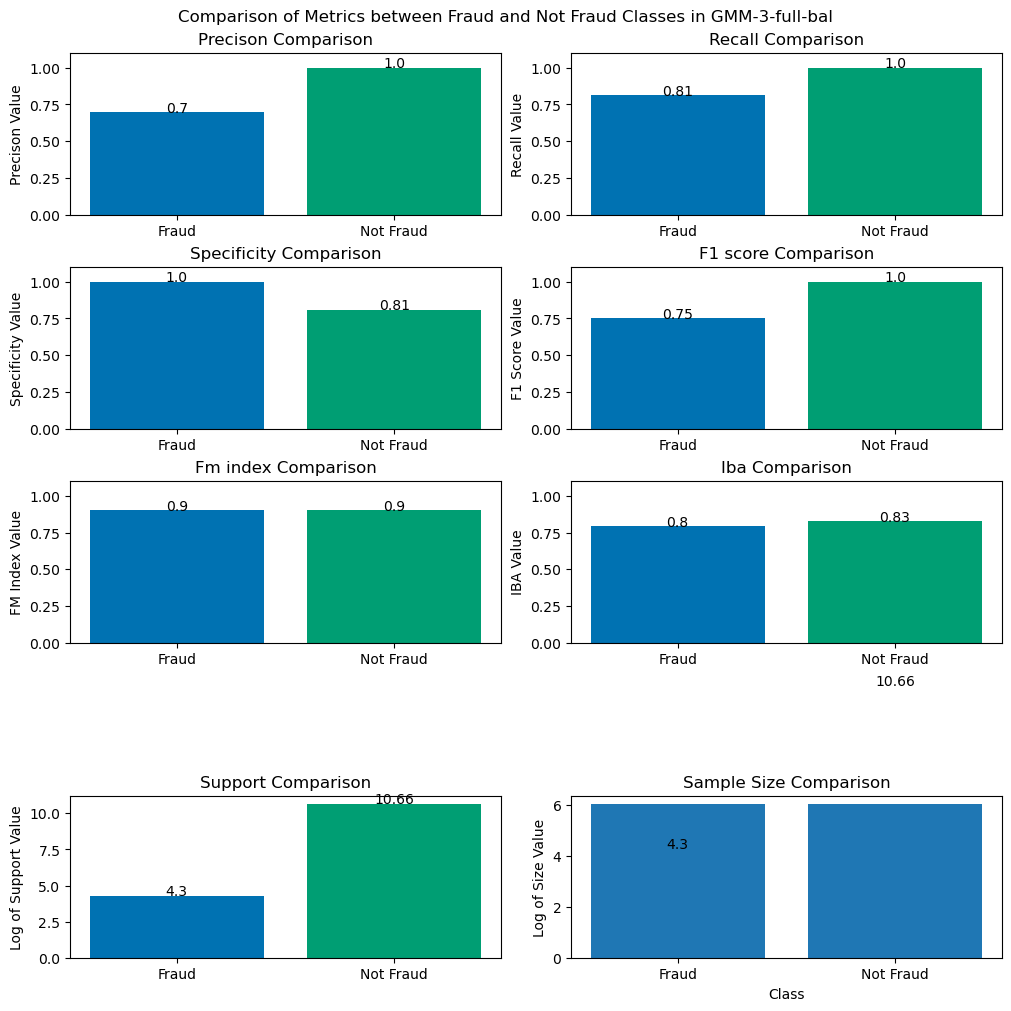

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6274/3970929101.py:72: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


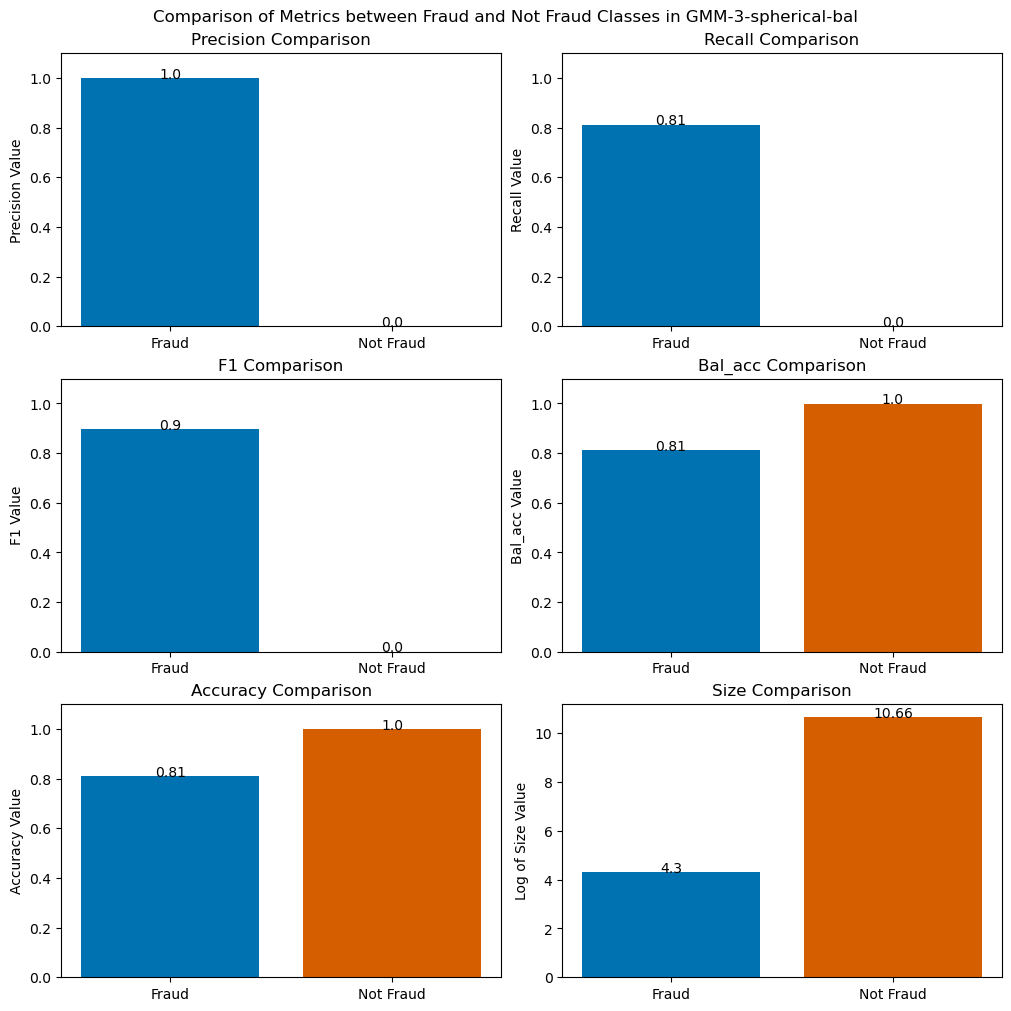

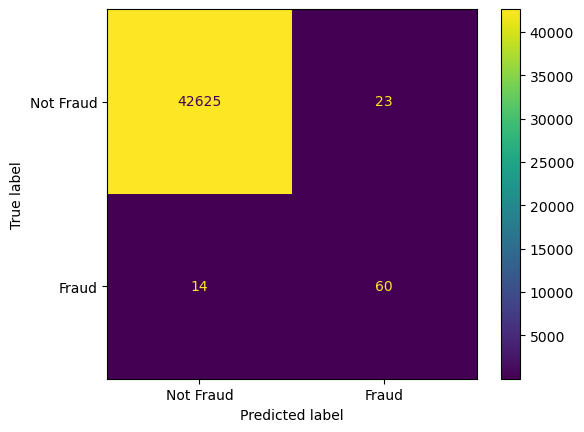

/tmp/ipykernel_6274/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


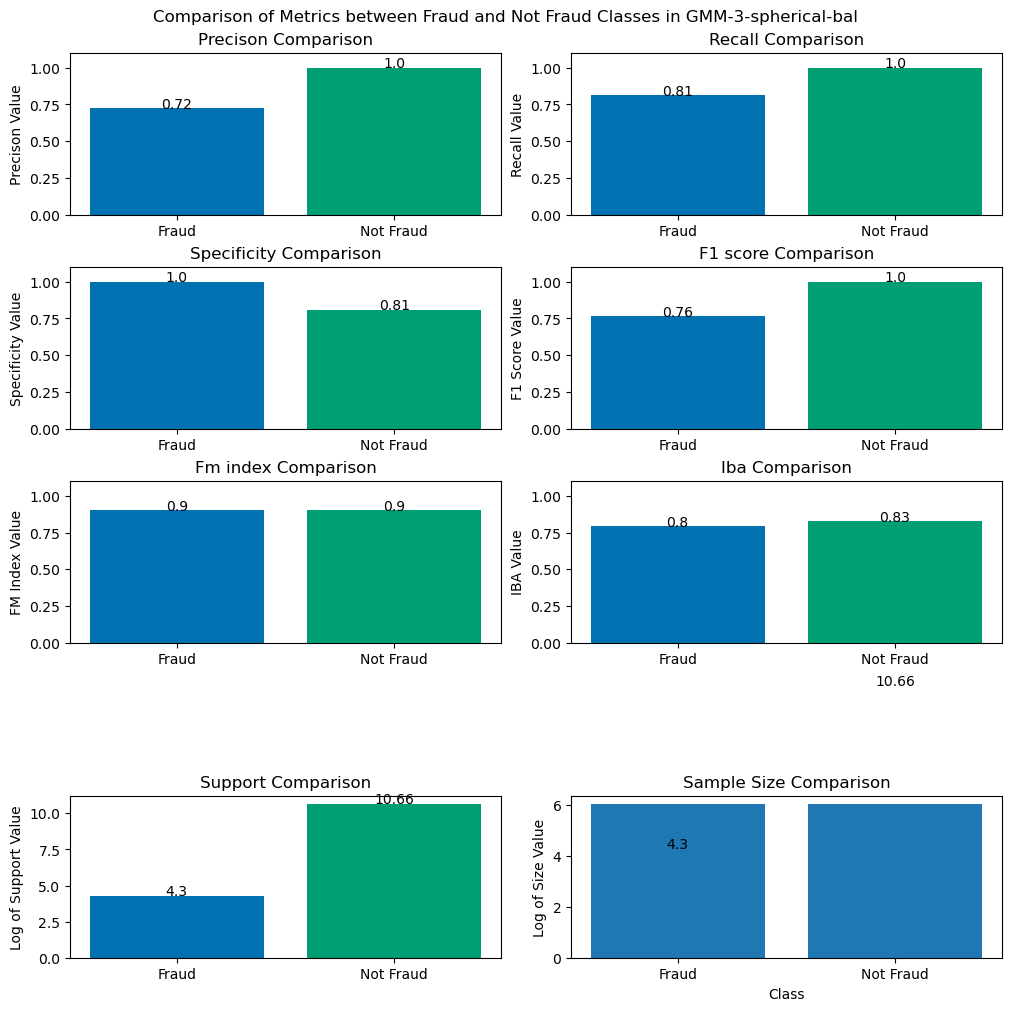

In [240]:
for j in enum:
    name, i, d = j
    if d:
        x_t, y_t = new_x_train[i], new_y_train[i]
    else:
        x_t, y_t = new_x_train1[i], new_y_train1[i]

    model, r1, r2, df = classify((x_t, y_t), (X_test, y_test), name=name, balanced=False)
    classifiers[name] = model
    sk_reports[name] = r1
    im_reports[name] = r2
    total_df[name] = df

In [241]:
comp_df = pd.concat(total_df, axis=0)

In [242]:
comp_df

,,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Vanilla-Unbalanced,Score,0.903846,0.635135,0.746032,0.817509,0.757335,0.999251,0.817509,0.574696,5417.448649,0.364908,Vanilla-Unbalanced
Vanilla-balanced,Score,0.065686,0.905405,0.122486,0.94153,0.240534,0.977529,0.94153,0.059637,40.518079,0.096757,Vanilla-balanced
GMM-13-diag-unbal,Score,0.046545,0.864865,0.088337,0.917062,0.196527,0.969079,0.917062,0.04049,28.134826,0.139421,GMM-13-diag-unbal
GMM-3-full-unbal,Score,0.689655,0.810811,0.745342,0.905089,0.747313,0.99904,0.905089,0.559508,1280.720721,0.189309,GMM-3-full-unbal
GMM-3-spherical-unbal,Score,0.722892,0.810811,0.764331,0.905136,0.765162,0.999134,0.905136,0.586456,1503.454759,0.189291,GMM-3-spherical-unbal
GMM-13-diag-bal,Score,0.07075,0.905405,0.131244,0.942386,0.249898,0.979238,0.942386,0.064221,43.879238,0.096588,GMM-13-diag-bal
GMM-3-full-bal,Score,0.697674,0.810811,0.75,0.905101,0.751659,0.999064,0.905101,0.56601,1329.97921,0.189305,GMM-3-full-bal
GMM-3-spherical-bal,Score,0.722892,0.810811,0.764331,0.905136,0.765162,0.999134,0.905136,0.586456,1503.454759,0.189291,GMM-3-spherical-bal


In [243]:
comp_df.to_csv('comparison_metrics.csv', index=False)

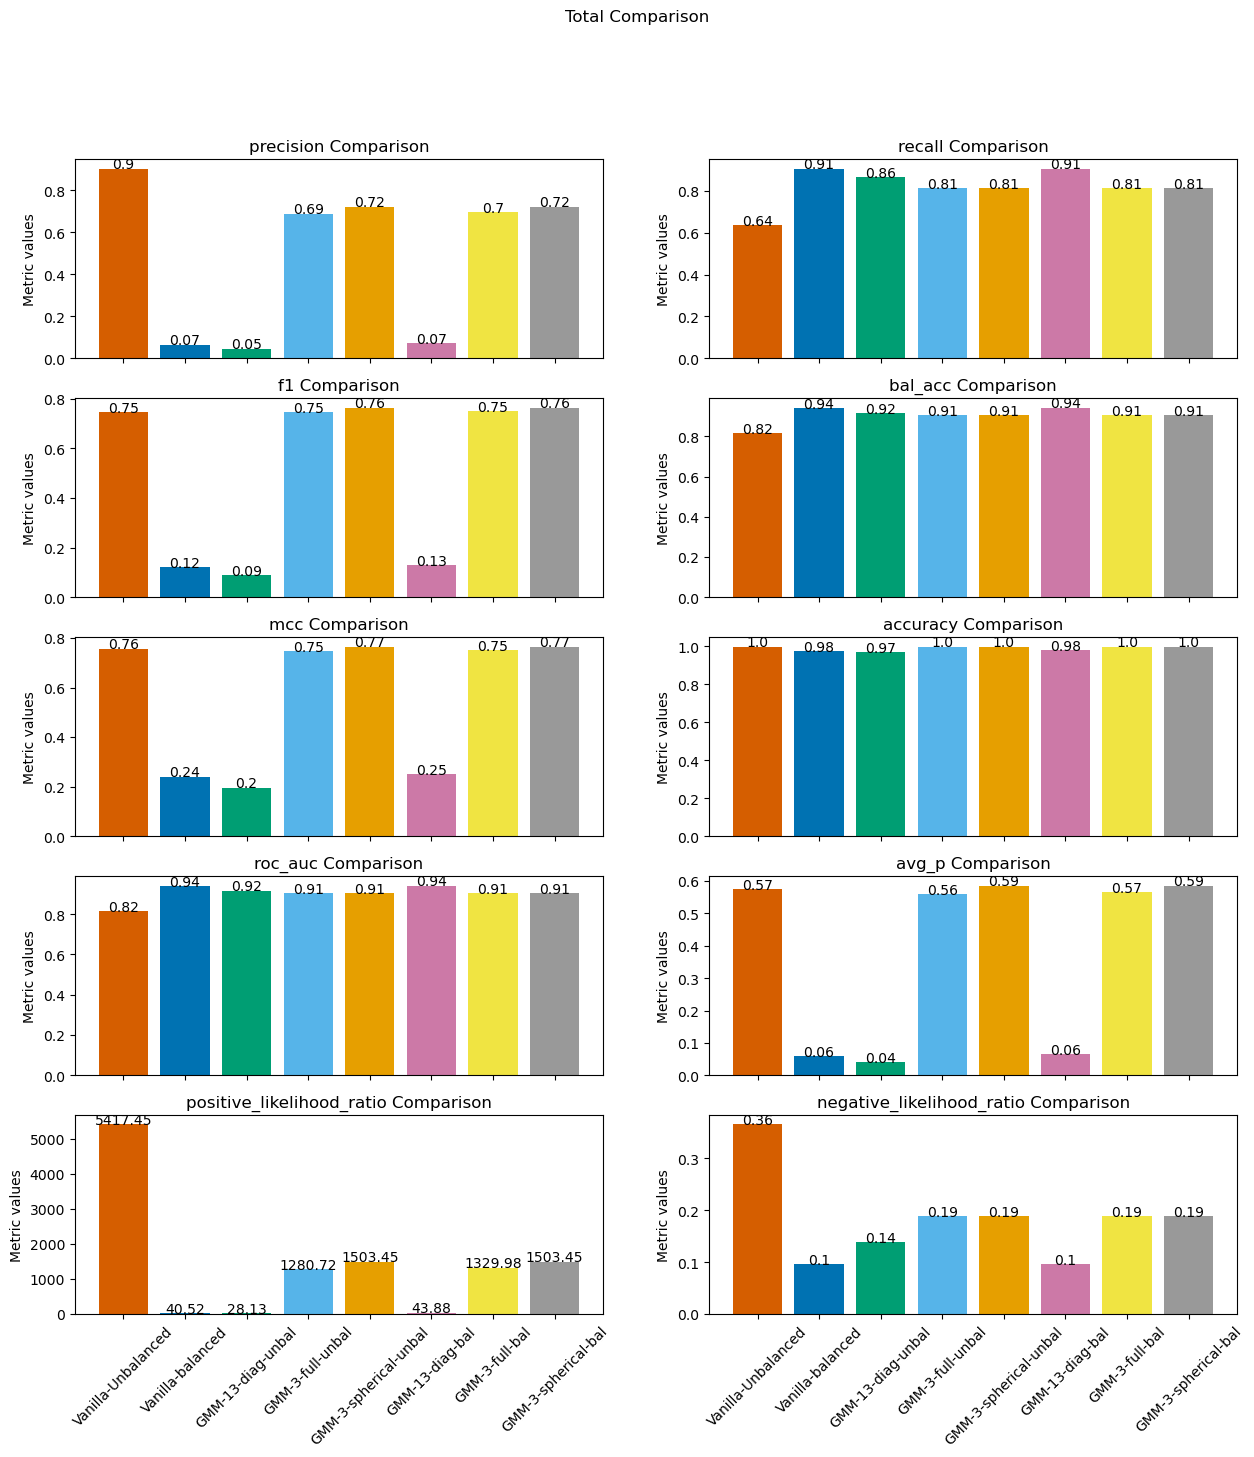

In [247]:
x = list(comp_df['name'])
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canaryp,  Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]

i, j = 0, 0
for k in comp_df.columns:
    if k != 'name':
        ax = axs[i, j]
        l = list(comp_df[k])
        ax.bar(x, height=l, color=color_palette)
        ax.set_ylabel("Metric values")
        if i == 4:
            ax.tick_params(axis='x', labelrotation=45)
        else:
            ax.set_xticklabels([]) 
        ax.set_title(f"{k} Comparison")

        for q in range(len(l)):
            ax.text(q, l[q], np.round(l[q], 2), ha='center')  # Aligning text at center

        j += 1
        if j == 2:
            i += 1
            j = 0
fig.suptitle("Total Comparison")
plt.savefig("images/total_comp.png")
plt.show()

Observations:
1. Among the GMM types, Diag performs best for Recall, Equal for Accuracy and Balanced Accuracy and Worst for Precision, F1, MCC, and Average Precision; Spherical and Full perform equally
2. GMM + CBU performs better than just GMM and comparable to Vanilla version
3. In general, applying GMMs helps in model performance with a more balanced precision, recall and F1
4. Best methods seems to be 3-GMMs with spherical covariance with either CBU or not and 3-GMMs with full covariance + CBU

In [248]:
pr_curves = {report:(sk_reports[report]['pr_curve'], sk_reports[report]['avg_p']) for report in sk_reports}
roc_curves = {report:(sk_reports[report]['roc_curve'], sk_reports[report]['roc_auc']) for report in sk_reports}

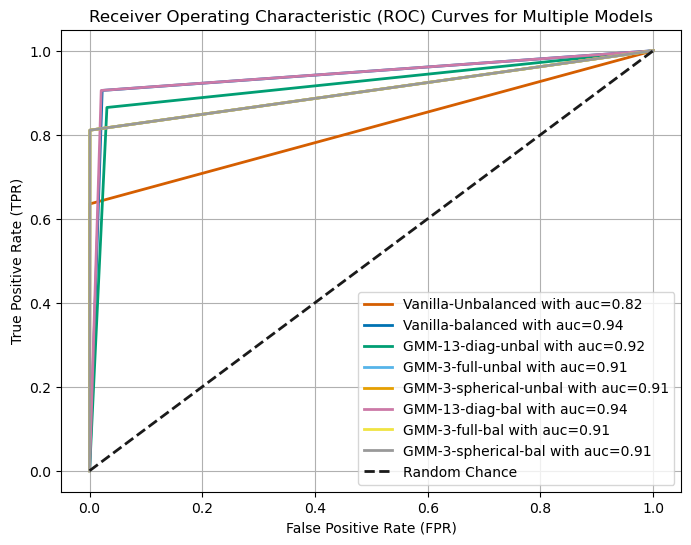

In [249]:
plt.figure(figsize=(8, 6))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canary Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]
k = list(roc_curves.keys())
for i in range(len(k)):
    roc, roc_auc = roc_curves[k[i]]
    fpr, tpr, thresholds = roc
    plt.plot(fpr, tpr, color=color_palette[i], lw=2, label=f"{k[i]} with auc={roc_auc:.2f}") # Plot Model 1's ROC curve

# Plot the random chance line (diagonal line)
plt.plot([0, 1], [0, 1], color=color_palette[-1], lw=2, linestyle='--', label='Random Chance')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves for Multiple Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig("images/roc_curves.png")
plt.show()

Observations:
1. GMM-13-diag + CBU has the highest AUC along with Balanced Logistic Regression
2. Unbalanced Logistic Regression has the least
3. The other models perform comparable to each other

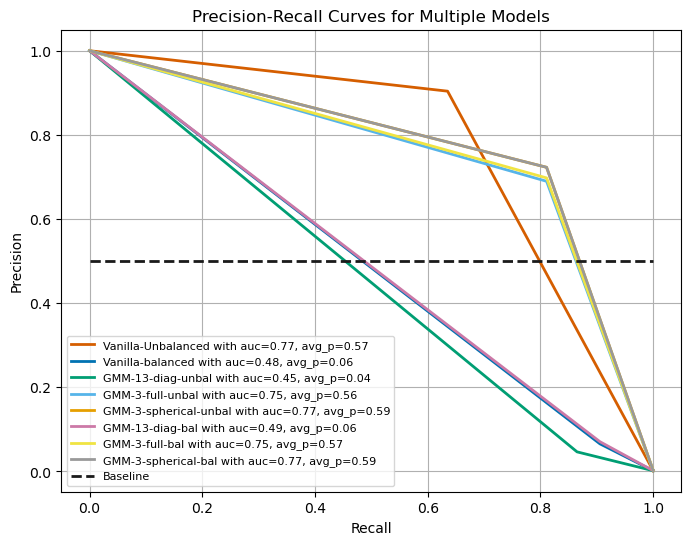

In [250]:
plt.figure(figsize=(8, 6))
color_palette = [
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canaryp,  Yellow
    '#999999',   # Gray
    '#882255',
    '#1A1A1A',  # Onyx
]
k = list(pr_curves.keys())
for i in range(len(k)):
    pr, avg_p = pr_curves[k[i]]
    p, r, thresholds = pr
    pr_auc = auc(p, r)
    plt.plot(r, p, color=color_palette[i], lw=2, label=f"{k[i]} with auc={pr_auc:.2f}, avg_p={avg_p:.2f}") # Plot Model 1's ROC curve

# Plot the random chance line (diagonal line)
plt.plot([0, 1], [0.5, 0.5], color=color_palette[-1], lw=2, linestyle='--', label='Baseline')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves for Multiple Models')
plt.legend(loc='lower left', fontsize=8)
plt.grid(True)
plt.savefig("images/pr_curves.png")
plt.show()

Observations:
1. Most of the GMM models perform well
2. Balanced Logistic Regression, GMM-13-Diag perform lower than satisfactory

## Conclusion

We can now safely conclude that GMMs indeed help in the model performance on the minority class, as it captures the underlying distribution of the class and samples from that, leading to better representation and hence performance. There are cases where an additional CBU also benefits.<br>
The preferred methods are **3-GMMs with spherical or full covariance**